## Futures Volatility

Before Proceeding, brief introduction are in orders. 

Suppose we now have daily return time series $\{r_t\}_{t=1:\infty}$
$$
r_t = \log \left( \frac{F_t}{F_{t-1}} \right)
$$

On futures, it has to be done by switching main futures traded on the exchange.

Historical volatility is calculated based on a selected period of windows, suppose there are $n$ observations.

$$
\sigma^{\text{HV}}_t = \sqrt{\frac{244}{n-1} \sum^n_{i=1} \big( r_{t-i} - \bar{r}_{t-n:t-1} \big)^2  }
$$

Where
$$
\bar{r}_{t-n:t-1} = \frac{1}{n} \sum^n_{i=1} r_{t-i}
$$

Conditional Volatility is a latent variable, that is not directly observed or computed.

Suppose the mean function of return takes following form
$$
r_t = \mu + \epsilon_t \qquad \epsilon_t = \sigma_t z_t 
$$
Where $z_t \sim \text{WN}(0,1)$, that is 
$$
\mathbb{E}(z_t) = 0 \qquad \mathrm{Var}(z_t) = 1
$$
Classical choices for $z_t$ are Gaussian and Student-t Distribution.

Volatility proxy, is 
$$
\begin{aligned}
\mathbb{E}(r_t^2 \mid \mathcal{F}_{t-1}) & = \mathbb{E}\big((\mu + \sigma_t z_t )^2 \mid \mathcal{F}_{t-1}\big) \\[7pt]
& = \mu^2 + 2 \sigma_t \mathbb{E}\big(z_t \mid \mathcal{F}_{t-1} \big) + \sigma^2_t \mathbb{E}\big(z_t^2 \mid \mathcal{F}_{t-1} \big) \\[7pt]
& = \mu^2 + \sigma^2_t \to \sigma^2_t \qquad \mu^2 \to 0
\end{aligned}
$$
Under such circumstances, given the volatility proxy deliberately chosen to be $r_t^2$, the only sounding loss function would be MSE and QLIKE. Which are followed by

MSE
$$
\text{MSE}_{t+h|t} = \frac{1}{n}\sum^n_{i=1} (\sigma^2_{t+h} - \hat{\sigma}^2_{t+h|t})^2
$$

QLIKE
$$
\text{QLIKE}_{t+h|t} = \frac{1}{n}\sum^n_{i=1} \left(\frac{\sigma^2_{t+h}}{\hat{\sigma}^2_{t+h|t}} - \ln \left( \frac{\sigma^2_{t+h}}{\hat{\sigma}^2_{t+h|t}}\right) -1\right)
$$

### SQL Query

In [ ]:
!mamba install pandas matplotlib scipy

In [ ]:
import sqlite3
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

Connection = sqlite3.connect("commodity_options.db")

tables = pd.read_sql_query("SELECT name FROM sqlite_master WHERE type='table'", Connection)
print(tables)

In [ ]:
title = "futures_daily"
table = pd.read_sql_query(f'PRAGMA table_info("{title}")', Connection)[["name","type"]].to_string(index=False)
print(table)

In [ ]:
talbe = pd.read_sql_query(f'SELECT * FROM"{title}" LIMIT 10', Connection)
display(talbe)

In [ ]:
SourCrudeOil = pd.read_sql_query("""
SELECT date,underlying,open,high,low,close,settlement,prev_settlement,volume,total_turnover,open_interest 
FROM futures_daily
WHERE underlying GLOB 'sc[0-9]*'
AND time_slot = '15:00'
ORDER BY date ASC, underlying ASC
""", Connection)

### ARFIMA FIGARCH

Reviewing/Recapitulating on Time Series Modelling.

For an ARMA$(p,q)$ process

$$
r_t = c + \sum^p_{i=1} \phi_i r_{t-i} + \sum^q_{j=1} \theta_j \epsilon_{t-j} + \epsilon_t  \qquad \epsilon_t \sim \text{WN}(0,\sigma_\epsilon^2)
$$

Defining Lag Operator $L$ as
$$
L r_t = r_{t-1}
$$

ARMA$(p,q)$ can be rewritten as
$$
\Phi(L)r_t = c + \Theta(L)\epsilon_t
$$
Where
$$
\Phi(L) = 1 - \sum^p_{i=1} \phi_i L^i \qquad \Theta(L) = 1 + \sum^q_{j=1} \theta_j L^j
$$

For an ARFIMA$(p,d,q)$ process

$$
\Phi(L)(1-L)^d r_t = c + \Theta(L)\epsilon_t
$$

Consider a binomial expansion
$$
\begin{aligned}
(1-L)^d & = \sum^\infty_{k=0} (-1)^k \frac{d!}{(d-k)!k!} L^k \\[7pt]
& = 1 - dL + \frac{d(d-1)}{2}L^2 - \frac{d(d-1)(d-2)}{6}L^3
\end{aligned}
$$

For a GARCH(p,q) process
$$
\begin{aligned}
\sigma_t^2 & = \omega + \sum^p_{i=1} \alpha_i \epsilon^2_{t-i} + + \sum^q_{j=1} \beta_j \sigma^2_{t-j} \\[7pt]
\sigma_t^2 & = \omega + \sum^p_{i=1} \alpha_i L^i \epsilon^2_{t} + + \sum^q_{j=1} \beta_j L^j \sigma^2_{t} \\[7pt]
\big(1 - \sum^q_{j=1}\beta_jL^j\big) \sigma_t^2 & = \omega + \sum^p_{i=1}\alpha_i L^i \epsilon^2_{t} \\[7pt]
\big(1 - \beta(L) \big) \sigma_t^2 & = \omega + \alpha(L) \epsilon^2_{t}
\end{aligned}
$$
Defining Martingagle Difference Sequence $\nu_t$
$$
\nu_t = \epsilon_t^2 - \sigma^2_t 
$$
One can easily see that
$$
\mathbb{E}(\nu_t \mid \mathcal{F}_{t-1}) = \mathbb{E}(\epsilon_t^2  \mid \mathcal{F}_{t-1}) - \sigma_t^2 = 0
$$
Substituting back
$$
\begin{aligned}
\big(1 - \beta(L) \big) (\epsilon_t^2 - \nu_t) & = \omega + \alpha(L) \epsilon^2_{t}\\[7pt]
\big(1 - \alpha(L) - \beta(L) \big) \epsilon_t^2  & =  \omega + \big(1 - \beta(L)\big)\nu_t
\end{aligned}
$$

For a FIGARCH$(p,d,q)$ processs
$$
\big(1 - \alpha(L) - \beta(L) \big )\big(1-L \big)^d \epsilon_t^2  =  \omega + \big(1 - \beta(L)\big)\nu_t
$$

A more common reparameterisation is
$$
\big(1 - \beta(L)\big)\sigma^2_t = \omega + \left(1 - \beta(L) - \big(1-\alpha(L) -\beta(L) \big)\big(1-L\big)^d \right) \epsilon_t^2
$$


Take ARMA(1,1)-GARCH(1,1) as an example. Consider time series $\{r_t\}_{t=1:n}$
Mean function
$$
r_t = \mu + \phi r_{t-1} + \theta \epsilon_t
$$
Where
$$
\epsilon_t = \sigma_t z_t \qquad z_t \sim N(0,1)
$$
Note that $z_t$ can also be drawn from student t distribution.

Volatility function
$$
\sigma^2_t = \omega + \alpha \epsilon^2_{t-1} + \beta \sigma^2_{t-1}
$$

One step ahead gives 
$$
\hat{\sigma}^2_{t+1|t} = \mathrm{Var}(r_{t+1}\mid \mathcal{F}_t) 
$$

It is Clearly that
$$
\mathbb{E} ( \epsilon_t ) = 0 \qquad \mathrm{Var} ( \epsilon_t ) = \sigma^2_t
$$
Suppose that the mean function can be summarised as
$$
r_t = m_t + \epsilon_t
$$
Where $m_t$ is the conditional mean of return $r_t$. 

One can naturally say that
$$
\mathbb{E} ( \epsilon^2_t ) = \mathbb{E}(r_t - m_t)^2
$$
Also Clearly
$$
\mathbb{E} (r_{t+1}^2 \mid \mathcal{F}_t) = \sigma^2_{t+1|t} + \hat{m}^2_{t+1} 
$$

For daily return time series $r_t$, it is safe to say that we can ignore the conditional mean term $m_t$.

This gives a volatility proxy
$$
\sigma^2_t = r^2_t 
$$


In [31]:
Futures = pd.read_sql_query("""
SELECT
    date,
    underlying,
    open,
    high,
    low,
    close,
    settlement,
    prev_settlement,
    volume,
    total_turnover,
    open_interest
FROM futures_daily
WHERE underlying GLOB 'sc[0-9]*'
  AND time_slot = '15:00'
ORDER BY date ASC, underlying ASC
""", Connection)

Futures['date'] = pd.to_datetime(Futures['date'])

Futures = Futures.sort_values(['underlying', 'date'])

# Calculate Each Return on Each Contracts
Futures['return'] = Futures.groupby('underlying')['close'].transform(
    lambda x: np.log(x / x.shift(1))
)

# Selecting Maximum Open Interest as Main Contracts
idx = Futures.groupby('date')['open_interest'].idxmax()

# Use .loc[], not .iloc[]
Futures = Futures.loc[idx].sort_values('date')

In [32]:
# 每天的主力期货：日期、合约代码、收盘价
MainFutures = Futures[['date', 'underlying', 'close']].copy()

MainFutures = MainFutures.rename(columns={
    'underlying': 'main_underlying',
    'close': 'futures_close'
})

# 统一标的代码格式，例如 sc2109
MainFutures['main_underlying'] = (
    MainFutures['main_underlying']
    .str.split('.').str[0].str.lower()
)

# 读取原油期权 IV，只保留 INE 的收盘快照
OptionsIV = pd.read_sql_query("""
    SELECT date, vt_symbol, iv, iv_trade
    FROM option_iv_snapshots
    WHERE LOWER(vt_symbol) LIKE 'sc%'
      AND UPPER(vt_symbol) LIKE '%.INE'
      AND time_slot = '15:00'
    ORDER BY date, vt_symbol
""", Connection)

OptionsIV['date'] = pd.to_datetime(OptionsIV['date'])

# 拆解期权代码，例如 sc2109C390.INE：
# 标的 sc2109、类型 C、行权价 390
Parts = OptionsIV['vt_symbol'].str.extract(
    r'(?i)^(sc\d+)-?([CP])-?(\d+(?:\.\d+)?)\.INE$'
)

OptionsIV['underlying'] = Parts[0].str.lower()
OptionsIV['option_type'] = Parts[1].str.upper()
OptionsIV['strike'] = pd.to_numeric(Parts[2])

# 检查是否存在无法解析的合约代码
if Parts.isna().any(axis=1).any():
    raise ValueError("存在无法解析的期权代码，请检查 OptionsIV 中的 vt_symbol。")

# 按“日期 + 标的合约”匹配：
# 主力期货换月时，对应的期权链同步换月
MainOptionsIV = OptionsIV.merge(
    MainFutures,
    left_on=['date', 'underlying'],
    right_on=['date', 'main_underlying'],
    how='inner',
    validate='many_to_one'
)

MainOptionsIV = (
    MainOptionsIV[
        ['date', 'underlying', 'futures_close',
         'vt_symbol', 'option_type', 'strike', 'iv', 'iv_trade']
    ]
    .sort_values(['date', 'strike', 'option_type'])
    .reset_index(drop=True)
)

display(MainOptionsIV.head(20))

,date,underlying,futures_close,vt_symbol,option_type,strike,iv,iv_trade
0,2021-07-14,sc2109,466.8,sc2109P390.INE,P,390,0.326646,0.326646
1,2021-07-14,sc2109,466.8,sc2109P395.INE,P,395,0.301499,0.301499
2,2021-07-14,sc2109,466.8,sc2109P400.INE,P,400,0.301816,0.301816
3,2021-07-14,sc2109,466.8,sc2109P405.INE,P,405,0.293557,0.293557
4,2021-07-14,sc2109,466.8,sc2109P410.INE,P,410,0.292393,0.292393
5,2021-07-14,sc2109,466.8,sc2109P415.INE,P,415,0.289306,0.289306
6,2021-07-14,sc2109,466.8,sc2109C420.INE,C,420,0.259436,0.259436
7,2021-07-14,sc2109,466.8,sc2109P420.INE,P,420,0.284450,0.284450
8,2021-07-14,sc2109,466.8,sc2109C425.INE,C,425,0.272007,0.272007
9,2021-07-14,sc2109,466.8,sc2109P425.INE,P,425,0.283353,0.283353


In [34]:
MissingDates = MainFutures.loc[
    ~MainFutures['date'].isin(MainOptionsIV['date']),
    ['date', 'main_underlying']
]

print("没有匹配到期权 IV 的主力日期数：", len(MissingDates))
display(MissingDates.tail(10))

没有匹配到期权 IV 的主力日期数： 819


,date,main_underlying
22635,2022-12-07,sc2301
22955,2022-12-29,sc2302
22975,2022-12-30,sc2302
25115,2023-06-13,sc2307
28335,2024-02-06,sc2403
28355,2024-02-07,sc2403
28755,2024-03-14,sc2404
29935,2024-06-13,sc2407
29955,2024-06-14,sc2407
30395,2024-07-16,sc2408


In [5]:
Futures = Futures.sort_values(['underlying', 'date'])

# Calculate Each Return on Each Contracts
Futures['return'] = Futures.groupby('underlying')['close'].transform(
    lambda x: np.log(x / x.shift(1))
)

# Selecting Maximum Open Interest as Main Contracts
idx = Futures.groupby('date')['open_interest'].idxmax()

# Use .loc[], not .iloc[]
SC = Futures.loc[idx].sort_values('date')

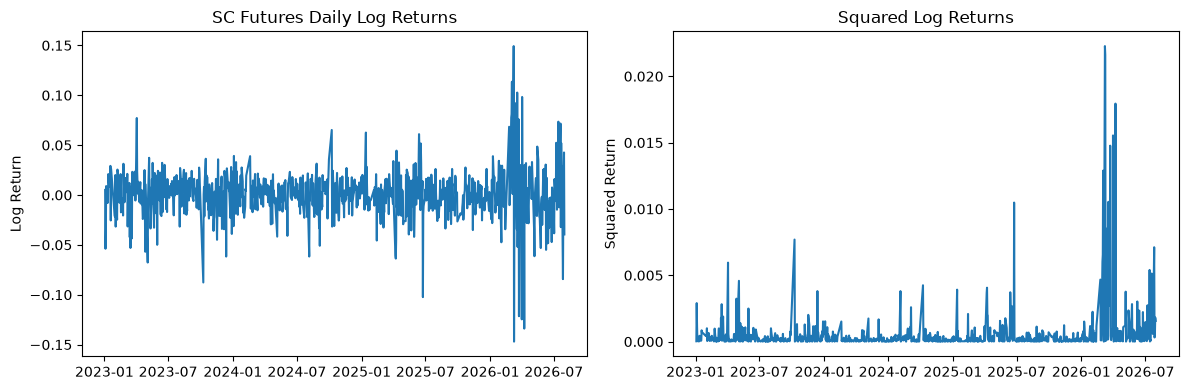

In [6]:
SC = SC[SC['date'] >= '2023-01-01'].copy()

SC = SC.sort_values(
    ['date', 'underlying']
).reset_index(drop=True)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].plot(SC['date'], SC['return'])
ax[0].set_title('SC Futures Daily Log Returns')
ax[0].set_ylabel('Log Return')

ax[1].plot(SC['date'], SC['return']**2)
ax[1].set_title('Squared Log Returns')
ax[1].set_ylabel('Squared Return')

plt.tight_layout()
plt.show()

### ARIMA(1,1,1)-GARCH(1,1)

Kang, S.H. and Yoon, S.M., 2013. Modeling and forecasting the volatility of petroleum futures prices. Energy Economics, 36, pp.354-362.

Volatility Proxy
$$
\sigma^2_t = r_t^2
$$
It is a pretty noisy proxy for actual volatility.

Where
$$
r_t = 100 \times \ln \frac{F_t}{F_{t-1}}
$$
$$
x_t = \Delta r_t = r_t - r_{t-1}
$$
Mean Function
$$
x_t = \psi x_{t-1} +\theta \epsilon_{t-1} + \epsilon_t
$$
Where
$$
\epsilon_t = \sqrt{h_t} z_t \qquad z_t \sim N(0,1)
$$
GARCH(1,1)
$$
h_t = \omega + \alpha \epsilon^2_{t-1} + \beta h_{t-1}
$$

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.signal import lfilter
from scipy.optimize import minimize


# ============================================================
# 0. 设置数据范围、滚动窗口和预测期限
# ============================================================

WINDOW = 244
HORIZONS = (1, 5, 22)

DATA_START = "2023-01-01"
DATA_END = "2026-07-31"

# None：第一个244日训练窗口结束后立即开始预测。
# 也可以填写日期，例如 "2024-01-01"。
FORECAST_START = None

In [ ]:
# ============================================================
# 1. 整理收益率
# ============================================================
# 直接使用SC中按各合约分别计算的return。
# 不对拼接后的主力合约close再次计算收益率，避免换月价差。
#
# 原始return为小数形式：0.01表示约1%。
# 乘100后转换为百分数形式：1表示约1%。
# 后续创新方差和收益率平方均采用同一百分数平方单位。

data = SC[["date", "return"]].copy()
data["date"] = pd.to_datetime(data["date"], errors="raise")
data = data.sort_values("date").set_index("date")
data = data.loc[DATA_START:DATA_END]

if data.index.has_duplicates:
    raise ValueError("同一日期存在多行数据，请先处理重复日期。")

r = 100.0 * pd.to_numeric(data["return"], errors="raise")
r.name = "return_pct"

if not np.isfinite(r.to_numpy()).all():
    raise ValueError(
        "收益率存在NaN或无穷值，请先检查各合约价格和缺失日期。"
    )

max_horizon = max(HORIZONS)

if len(r) < WINDOW + max_horizon:
    raise ValueError(
        f"至少需要{WINDOW + max_horizon}个收益率，当前只有{len(r)}个。"
    )

print(f"收益率范围：{r.index[0].date()} 至 {r.index[-1].date()}")
print(f"收益率数量：{len(r)}")

In [ ]:
# ============================================================
# 2. 联合估计ARIMA(1,1,1)-GARCH(1,1)
# ============================================================
# 均值方程：
#   x_t = y_t - y_{t-1}
#   x_t = psi*x_{t-1} + epsilon_t + theta*epsilon_{t-1}
#
# 方差方程：
#   h_t = omega + alpha*epsilon_{t-1}^2 + beta*h_{t-1}
#
# 保持原代码的无漂移设定，共估计5个参数：
#   psi、theta、omega、alpha、beta。
#
# 一个244日收益率窗口经过差分后，实际用于似然的是243个观测。
# 内部缩放差分收益率，改善优化时不同参数的数值尺度。
# 返回结果时，将omega、残差和方差恢复到原始单位。

def fit_arima_garch(returns):

    y = np.asarray(returns, dtype=float)

    if len(y) < 30 or not np.isfinite(y).all():
        raise ValueError("训练数据不足或包含非有限值。")

    x_original = np.diff(y)
    scale = x_original.std()

    if scale <= 1e-12:
        raise ValueError("差分收益率变化过小，无法估计模型。")

    x = x_original / scale
    h0 = x.var()

    def filter_model(params):
        psi, theta, omega, alpha, beta = params

        # 根据ARMA递推计算创新epsilon。
        # lfilter默认将窗口之前的x和epsilon初始化为0。
        epsilon = lfilter([1.0, -psi], [1.0, theta], x)

        # GARCH递推可以写为：
        # h_t - beta*h_{t-1} = omega + alpha*epsilon_{t-1}^2
        # 使用lfilter完成递推，减少Python层面的逐日循环。
        forcing = np.empty_like(x)
        forcing[0] = h0
        forcing[1:] = omega + alpha * epsilon[:-1] ** 2

        variance = lfilter([1.0], [1.0, -beta], forcing)

        return epsilon, variance

    def negative_loglikelihood(params):
        epsilon, variance = filter_model(params)

        if (
            not np.isfinite(epsilon).all()
            or not np.isfinite(variance).all()
            or np.any(variance <= 0)
        ):
            return 1e100

        return 0.5 * np.sum(
            np.log(2.0 * np.pi)
            + np.log(variance)
            + epsilon ** 2 / variance
        )

    bounds = [
        (-0.995, 0.995),   # psi：AR系数
        (-0.995, 0.995),   # theta：MA系数
        (1e-10, None),     # omega：正的方差截距
        (0.0, 1.0),       # alpha：冲击系数
        (0.0, 1.0),       # beta：方差持续性系数
    ]

    constraints = [{
        "type": "ineq",
        "fun": lambda p: 1.0 - 1e-6 - p[3] - p[4]
    }]

    # 保留三个初始点，降低单一初始点导致局部最优的风险。
    best = None
    messages = []

    for psi0, theta0 in [(0.0, 0.0), (0.5, -0.5), (-0.5, 0.5)]:

        result = minimize(
            negative_loglikelihood,
            x0=[psi0, theta0, 0.05 * h0, 0.05, 0.90],
            method="SLSQP",
            bounds=bounds,
            constraints=constraints,
            options={"maxiter": 1000, "ftol": 1e-8}
        )

        messages.append(str(result.message))

        # 优化器报告成功后，额外检查参数及约束。
        p = result.x
        valid = (
            result.success
            and np.isfinite(result.fun)
            and np.isfinite(p).all()
            and all(
                lower - 1e-8 <= value
                and (upper is None or value <= upper + 1e-8)
                for value, (lower, upper) in zip(p, bounds)
            )
            and p[3] + p[4] <= 1.0 - 1e-6 + 1e-8
        )

        if valid and (best is None or result.fun < best.fun):
            best = result

    if best is None:
        raise RuntimeError("联合优化失败：" + " | ".join(messages))

    epsilon, variance = filter_model(best.x)

    params = best.x.copy()
    params[2] *= scale ** 2

    epsilon *= scale
    variance *= scale ** 2

    return {
        "params": pd.Series(
            params,
            index=["psi", "theta", "omega", "alpha", "beta"]
        ),
        "epsilon": epsilon,
        "variance": variance,
        "standardized_residuals": epsilon / np.sqrt(variance),
        "loglikelihood": -best.fun - len(x) * np.log(scale)
    }

In [ ]:
# ============================================================
# 3. 预测未来每一天的创新方差
# ============================================================
# 第1步使用训练窗口末尾的已估计创新和方差：
#   h_{t+1|t} = omega + alpha*epsilon_t^2 + beta*h_t
#
# 后续步骤使用E_t[epsilon_{t+j}^2] = E_t[h_{t+j}]：
#   h_{t+j|t} = omega + (alpha+beta)*h_{t+j-1|t}
#
# 返回未来第1至horizon日各自的创新方差。
# 不对这些方差求和，也不计算未来区间平均方差。

def forecast_arima_garch(fit, horizon):

    p = fit["params"]
    omega, alpha, beta = p[["omega", "alpha", "beta"]].to_numpy()

    forecasts = np.empty(horizon)

    forecasts[0] = (
        omega
        + alpha * fit["epsilon"][-1] ** 2
        + beta * fit["variance"][-1]
    )

    for j in range(1, horizon):
        forecasts[j] = omega + (alpha + beta) * forecasts[j - 1]

    return forecasts

In [ ]:
# ============================================================
# 4. 每日滚动244日窗口，预测1、5、22步
# ============================================================
# origin：最后一个训练观测的日期。
# target：向前h个收益率观测对应的日期。
#
# 每个窗口独立联合估计参数，不使用未来数据。
# 只保留仍能评价22步预测的起点，使三个期限的起点一致。
# 某个窗口估计失败时，记录原因，并跳过该起点的全部期限。

forecast_start = (
    pd.Timestamp(FORECAST_START)
    if FORECAST_START is not None else None
)

origins = [
    t for t in range(WINDOW - 1, len(r) - max_horizon)
    if forecast_start is None or r.index[t] >= forecast_start
]

if not origins:
    raise ValueError("指定范围内没有可评价的预测起点。")

prediction_rows = []
parameter_rows = []
failure_rows = []

for number, t in enumerate(origins, start=1):

    train = r.iloc[t - WINDOW + 1:t + 1]

    try:
        fit = fit_arima_garch(train)
        forecasts = forecast_arima_garch(fit, max_horizon)

    except (RuntimeError, ValueError) as error:
        failure_rows.append({
            "origin": r.index[t],
            "reason": str(error)
        })

    else:
        parameter_rows.append({
            "origin": r.index[t],
            "train_start": train.index[0],
            "train_end": train.index[-1],
            "n_train": len(train),
            **fit["params"].to_dict(),
            "loglikelihood": fit["loglikelihood"]
        })

        for h in HORIZONS:
            actual_return = float(r.iloc[t + h])

            prediction_rows.append({
                "origin": r.index[t],
                "target": r.index[t + h],
                "horizon": h,
                "innovation_variance": forecasts[h - 1],
                "actual_return": actual_return,
                "proxy": actual_return ** 2
            })

    if number % 50 == 0 or number == len(origins):
        print(
            f"已处理{number}/{len(origins)}个起点；"
            f"失败{len(failure_rows)}个。"
        )

In [ ]:
# ============================================================
# 5. 整理预测、参数和失败记录，计算MSE与MAE
# ============================================================
# error = 创新方差预测 - 目标日收益率平方。
# MSE和MAE均直接在方差尺度上计算，不进行开方或年化。

forecast_table = pd.DataFrame(prediction_rows)
parameter_table = pd.DataFrame(parameter_rows)
failure_table = pd.DataFrame(
    failure_rows, columns=["origin", "reason"]
)

if forecast_table.empty:
    raise RuntimeError("所有起点均估计失败，请查看failure_table。")

forecast_table["error"] = (
    forecast_table["innovation_variance"] - forecast_table["proxy"]
)
forecast_table["squared_error"] = forecast_table["error"] ** 2
forecast_table["absolute_error"] = forecast_table["error"].abs()

evaluation = forecast_table.groupby("horizon").agg(
    N=("error", "size"),
    MSE=("squared_error", "mean"),
    MAE=("absolute_error", "mean")
)

parameter_table["persistence"] = (
    parameter_table["alpha"] + parameter_table["beta"]
)

print("\nARIMA(1,1,1)-GARCH(1,1)：样本外评价")
print(evaluation)

print("\n预测结果前六行：")
print(forecast_table.head(6))

print("\n首个训练窗口：")
print(parameter_table.iloc[0])

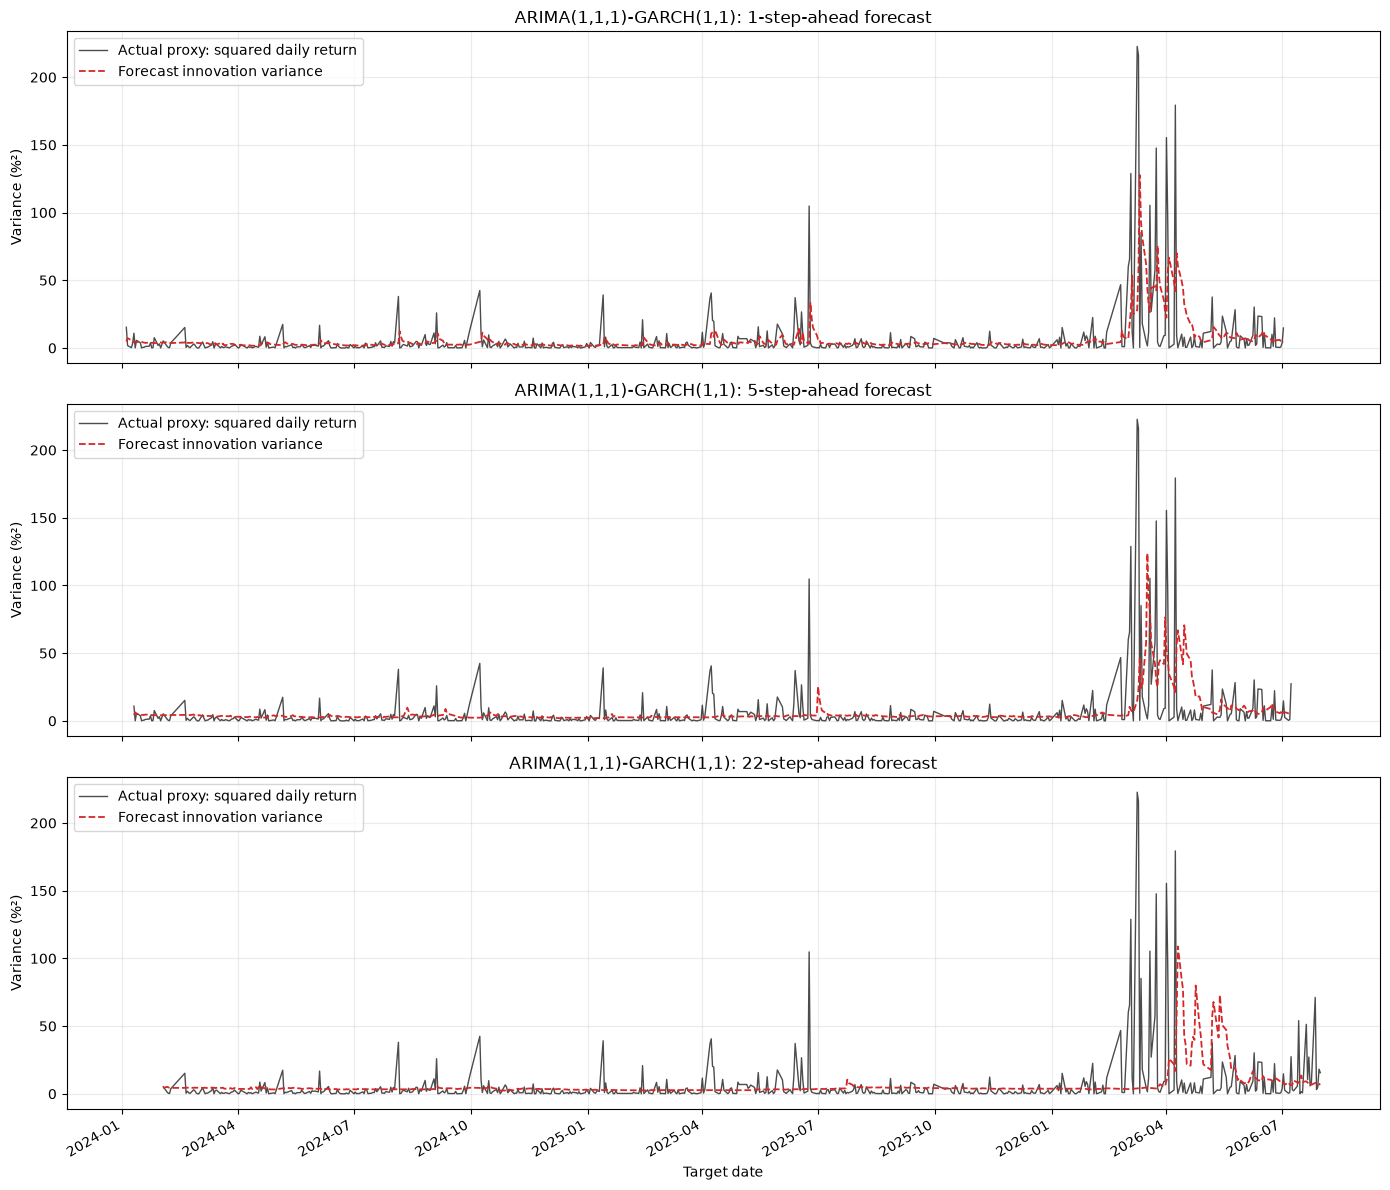

In [15]:
# ============================================================
# 6. 按目标日期绘制预测方差与实际proxy
# ============================================================

fig, axes = plt.subplots(
    len(HORIZONS), 1,
    figsize=(14, 4 * len(HORIZONS)),
    sharex=True,
    squeeze=False
)

for ax, h in zip(axes[:, 0], HORIZONS):

    plot_data = (
        forecast_table.loc[forecast_table["horizon"] == h]
        .sort_values("target")
    )

    ax.plot(
        plot_data["target"],
        plot_data["proxy"],
        color="black",
        linewidth=1,
        alpha=0.7,
        label="Actual proxy: squared daily return"
    )

    ax.plot(
        plot_data["target"],
        plot_data["innovation_variance"],
        color="tab:red",
        linestyle="--",
        linewidth=1.3,
        label="Forecast innovation variance"
    )

    ax.set_title(f"ARIMA(1,1,1)-GARCH(1,1): {h}-step-ahead forecast")
    ax.set_ylabel("Variance (%²)")
    ax.grid(alpha=0.25)
    ax.legend()

axes[-1, 0].set_xlabel("Target date")

fig.autofmt_xdate()
plt.tight_layout()
plt.show()

### ARFIMA-GARCH(1,1)

In [16]:
# 如未安装，在 Jupyter 中先运行：
# %pip install numpy pandas scipy

import numpy as np
import pandas as pd

from scipy.signal import lfilter
from scipy.optimize import minimize


# ============================================================
# 0. 设置
# ============================================================

DATE_COL = "date"       # 修改；若日期已经是索引，设为 None
PRICE_COL = "close"     # 修改为你的价格列名

DATA_START = "2023-01-01"
DATA_END = "2026-07-31"

WINDOW = 244
HORIZONS = (1, 5, 22)

# None：第一个完整训练窗口之后开始预测
# 若只评价 2024 年起的预测，改为 "2024-01-01"
FORECAST_START = None

# 每个窗口重新搜索九组阶数
AR_ORDERS = (0, 1, 2)
MA_ORDERS = (0, 1, 2)

# 所有候选模型使用相同的似然起点
BURN = 10

# 初次检查时可设为 3，只运行前三个预测起点
# 正式跑全部数据时设为 None
MAX_ORIGINS = None

In [17]:
# ============================================================
# 1. 分数差分系数
# ============================================================

def fractional_weights(xi, length):
    """
    (1-L)^xi = sum_k weights[k] * L^k

    weights[0] = 1
    weights[k] = weights[k-1] * (k-1-xi)/k
    """
    weights = np.empty(length)
    weights[0] = 1.0

    for k in range(1, length):
        weights[k] = (
            weights[k - 1] * (k - 1 - xi) / k
        )

    return weights

In [18]:
# ============================================================
# 2. AR/MA 参数化，保证平稳与可逆
# ============================================================

def ar_coefficients(partial_parameters):
    """
    支持阶数 0、1、2。
    将 (-1,1) 内的参数映射成平稳 AR 系数。
    """
    k = np.asarray(partial_parameters, dtype=float)

    if len(k) == 0:
        return np.empty(0)

    if len(k) == 1:
        return np.array([k[0]])

    if len(k) == 2:
        return np.array([
            k[0] * (1.0 - k[1]),
            k[1]
        ])

    raise ValueError("这里只实现了 0、1、2 阶。")

In [19]:
# ============================================================
# 3. 联合估计一个固定阶数 ARFIMA(n,xi,s)-GARCH(1,1)
# ============================================================

def fit_arfima_garch(returns, n, s, burn=BURN):

    y_original = np.asarray(returns, dtype=float)

    if (
        len(y_original) <= burn + 20
        or not np.isfinite(y_original).all()
    ):
        raise ValueError("训练数据不足或含非有限值。")

    scale = np.std(y_original, ddof=0)

    if not np.isfinite(scale) or scale <= 1e-12:
        raise ValueError("收益率没有足够变化。")

    # 仅使用当前训练窗口进行缩放
    y = y_original / scale
    initial_variance = np.var(y)

    def unpack(params):
        mu = params[0]
        xi = params[1]

        # AR 多项式：1 - psi_1 L - ...
        psi = ar_coefficients(params[2:2 + n])

        # MA 多项式：1 + theta_1 L + ...
        # 取平稳 AR 多项式系数的负值，保证 MA 可逆
        theta = -ar_coefficients(
            params[2 + n:2 + n + s]
        )

        omega, alpha, beta = params[-3:]

        return mu, xi, psi, theta, omega, alpha, beta

    def filter_model(params):
        mu, xi, psi, theta, omega, alpha, beta = unpack(params)

        weights = fractional_weights(xi, len(y))

        # 窗口以前的中心化收益率设为零
        fractional_y = np.convolve(
            y - mu,
            weights
        )[:len(y)]

        # Psi(L) fractional_y = Theta(L) epsilon
        epsilon = lfilter(
            np.r_[1.0, -psi],
            np.r_[1.0, theta],
            fractional_y
        )

        variance = np.empty(len(y))
        variance[0] = initial_variance

        for t in range(1, len(y)):
            variance[t] = (
                omega
                + alpha * epsilon[t - 1] ** 2
                + beta * variance[t - 1]
            )

        return epsilon, variance

    def negative_loglikelihood(params):
        epsilon, variance = filter_model(params)

        if (
            not np.isfinite(epsilon).all()
            or not np.isfinite(variance).all()
            or np.any(variance <= 0)
        ):
            return 1e100

        terms = (
            np.log(2.0 * np.pi)
            + np.log(variance)
            + epsilon ** 2 / variance
        )

        return 0.5 * np.sum(terms[burn:])

    bounds = (
        [
            (None, None),   # mu
            (-0.49, 0.49)   # xi
        ]
        + [(-0.98, 0.98)] * (n + s)
        + [
            (1e-10, None),  # omega
            (0.0, 1.0),     # alpha
            (0.0, 1.0)      # beta
        ]
    )

    constraints = [{
        "type": "ineq",
        "fun": lambda p: 1.0 - 1e-6 - p[-2] - p[-1]
    }]

    successful_results = []
    messages = []

    # 三组不同初始参数
    for xi0, coefficient0 in [
        (-0.10, 0.0),
        (0.10, 0.20),
        (0.0, -0.20)
    ]:
        start = np.r_[
            np.mean(y),
            xi0,
            np.full(n + s, coefficient0),
            0.05 * initial_variance,
            0.05,
            0.90
        ]

        result = minimize(
            negative_loglikelihood,
            x0=start,
            method="SLSQP",
            bounds=bounds,
            constraints=constraints,
            options={
                "maxiter": 700,
                "ftol": 1e-7
            }
        )

        messages.append(str(result.message))

        if (
            result.success
            and np.isfinite(result.fun)
            and np.isfinite(result.x).all()
            and result.x[-2] + result.x[-1]
                <= 1.0 - 1e-6 + 1e-8
        ):
            successful_results.append(result)

    if not successful_results:
        raise RuntimeError(
            f"ARFIMA({n},xi,{s}) 联合估计失败："
            + " | ".join(messages)
        )

    best = min(
        successful_results,
        key=lambda result: result.fun
    )

    mu, xi, psi, theta, omega, alpha, beta = unpack(best.x)
    epsilon_scaled, variance_scaled = filter_model(best.x)

    # 恢复百分比收益率的原始单位
    epsilon = epsilon_scaled * scale
    variance = variance_scaled * scale ** 2

    n_likelihood = len(y) - burn

    loglikelihood = (
        -best.fun - n_likelihood * np.log(scale)
    )

    # mu, xi, omega, alpha, beta + AR/MA 系数
    parameter_count = n + s + 5

    aic = (
        -2.0 * loglikelihood
        + 2.0 * parameter_count
    )

    params = {
        "mu": mu * scale,
        "xi": xi,
        "omega": omega * scale ** 2,
        "alpha": alpha,
        "beta": beta
    }

    params.update({
        f"psi_{j + 1}": value
        for j, value in enumerate(psi)
    })

    params.update({
        f"theta_{j + 1}": value
        for j, value in enumerate(theta)
    })

    return {
        "n": n,
        "s": s,
        "params": pd.Series(params),
        "epsilon": epsilon,
        "variance": variance,
        "standardized_residuals": epsilon / np.sqrt(variance),
        "loglikelihood": loglikelihood,
        "AIC": aic,
        "K": parameter_count,
        "n_likelihood": n_likelihood
    }


In [20]:
# ============================================================
# 4. 在当前窗口内，按 AIC 选择 ARFIMA 阶数
# ============================================================

def select_arfima_garch(returns):

    successful_fits = []
    search_rows = []

    for n in AR_ORDERS:
        for s in MA_ORDERS:

            try:
                fit = fit_arfima_garch(returns, n=n, s=s)

            except (RuntimeError, ValueError) as error:
                search_rows.append({
                    "n": n,
                    "s": s,
                    "AIC": np.nan,
                    "success": False,
                    "reason": str(error)
                })

            else:
                successful_fits.append(fit)

                search_rows.append({
                    "n": n,
                    "s": s,
                    "AIC": fit["AIC"],
                    "success": True,
                    "reason": ""
                })

    search_table = pd.DataFrame(search_rows)

    if not successful_fits:
        raise RuntimeError("当前窗口的九组候选模型全部失败。")

    best_fit = min(
        successful_fits,
        key=lambda fit: fit["AIC"]
    )

    return best_fit, search_table

In [21]:
# ============================================================
# 5. 预测第 1 至 horizon 日的创新方差
# ============================================================

def forecast_garch_variance(fit, horizon):

    params = fit["params"]

    omega = params["omega"]
    alpha = params["alpha"]
    beta = params["beta"]

    forecasts = np.empty(horizon)

    forecasts[0] = (
        omega
        + alpha * fit["epsilon"][-1] ** 2
        + beta * fit["variance"][-1]
    )

    for j in range(1, horizon):
        forecasts[j] = (
            omega
            + (alpha + beta) * forecasts[j - 1]
        )

    return forecasts

In [22]:
# ============================================================
# 6. 从 SC 价格计算百分比对数收益率
# ============================================================

data = SC.copy()

if DATE_COL is None:
    data.index = pd.to_datetime(data.index, errors="raise")
else:
    data[DATE_COL] = pd.to_datetime(
        data[DATE_COL],
        errors="raise"
    )
    data = data.set_index(DATE_COL)

data = data.sort_index()
data = data.loc[DATA_START:DATA_END]

if data.index.has_duplicates:
    raise ValueError("交易日期存在重复，请先处理。")

price = pd.to_numeric(
    data[PRICE_COL],
    errors="raise"
).astype(float)

if (
    not np.isfinite(price.to_numpy()).all()
    or (price <= 0).any()
):
    raise ValueError("价格存在缺失值、无穷值或非正值。")

r = (
    100.0 * (np.log(price) - np.log(price.shift(1)))
).iloc[1:]

r.name = "return_pct"

max_horizon = max(HORIZONS)

if len(r) < WINDOW + max_horizon:
    raise ValueError("数据不足以训练并评价全部预测期限。")

print("收益率观测数：", len(r))
print("收益率起止日期：", r.index[0], "至", r.index[-1])

收益率观测数： 865
,收益率起止日期： 2023-01-04 00:00:00 至 2026-07-31 00:00:00


In [23]:
# ============================================================
# 7. 244 日滚动：每个窗口重新选阶、联合估计、预测
# ============================================================

forecast_start = (
    None
    if FORECAST_START is None
    else pd.Timestamp(FORECAST_START)
)

origins = [
    t
    for t in range(WINDOW - 1, len(r) - max_horizon)
    if (
        forecast_start is None
        or r.index[t] >= forecast_start
    )
]

if MAX_ORIGINS is not None:
    origins = origins[:MAX_ORIGINS]

if not origins:
    raise ValueError("没有符合条件的预测起点。")

prediction_rows = []
parameter_rows = []
search_tables = []
failure_rows = []

first_best_fit = None

for number, t in enumerate(origins, start=1):

    train = r.iloc[t - WINDOW + 1:t + 1]

    try:
        best_fit, search = select_arfima_garch(train)

        forecasts = forecast_garch_variance(
            best_fit,
            horizon=max_horizon
        )

    except (RuntimeError, ValueError) as error:
        failure_rows.append({
            "origin": r.index[t],
            "reason": str(error)
        })

    else:
        if first_best_fit is None:
            first_best_fit = best_fit

        search["origin"] = r.index[t]
        search_tables.append(search)

        parameter_rows.append({
            "origin": r.index[t],
            "train_start": train.index[0],
            "train_end": train.index[-1],
            "n_train": len(train),
            "n_best": best_fit["n"],
            "s_best": best_fit["s"],
            "AIC": best_fit["AIC"],
            "loglikelihood": best_fit["loglikelihood"],
            **best_fit["params"].to_dict()
        })

        for h in HORIZONS:
            actual_return = float(r.iloc[t + h])

            prediction_rows.append({
                "origin": r.index[t],
                "target": r.index[t + h],
                "horizon": h,
                "n_best": best_fit["n"],
                "s_best": best_fit["s"],
                "innovation_variance": float(forecasts[h - 1]),
                "actual_return": actual_return,
                "proxy": actual_return ** 2
            })

    if number % 10 == 0 or number == len(origins):
        print(
            f"已完成 {number}/{len(origins)} 个预测起点；"
            f"全部候选失败的起点数：{len(failure_rows)}"
        )

已完成 10/600 个预测起点；全部候选失败的起点数：0
,已完成 20/600 个预测起点；全部候选失败的起点数：0
,已完成 30/600 个预测起点；全部候选失败的起点数：0
,已完成 40/600 个预测起点；全部候选失败的起点数：0
,已完成 50/600 个预测起点；全部候选失败的起点数：0
,已完成 60/600 个预测起点；全部候选失败的起点数：0
,已完成 70/600 个预测起点；全部候选失败的起点数：0
,已完成 80/600 个预测起点；全部候选失败的起点数：0
,已完成 90/600 个预测起点；全部候选失败的起点数：0
,已完成 100/600 个预测起点；全部候选失败的起点数：0
,已完成 110/600 个预测起点；全部候选失败的起点数：0
,已完成 120/600 个预测起点；全部候选失败的起点数：0
,已完成 130/600 个预测起点；全部候选失败的起点数：0
,已完成 140/600 个预测起点；全部候选失败的起点数：0
,已完成 150/600 个预测起点；全部候选失败的起点数：0
,已完成 160/600 个预测起点；全部候选失败的起点数：0
,已完成 170/600 个预测起点；全部候选失败的起点数：0
,已完成 180/600 个预测起点；全部候选失败的起点数：0
,已完成 190/600 个预测起点；全部候选失败的起点数：0
,已完成 200/600 个预测起点；全部候选失败的起点数：0
,已完成 210/600 个预测起点；全部候选失败的起点数：0
,已完成 220/600 个预测起点；全部候选失败的起点数：0
,已完成 230/600 个预测起点；全部候选失败的起点数：0
,已完成 240/600 个预测起点；全部候选失败的起点数：0
,已完成 250/600 个预测起点；全部候选失败的起点数：0
,已完成 260/600 个预测起点；全部候选失败的起点数：0
,已完成 270/600 个预测起点；全部候选失败的起点数：0
,已完成 280/600 个预测起点；全部候选失败的起点数：0
,已完成 290/600 个预测起点；全部候选失败的起点数：0
,已完成 300/600 个预测起点；全部候选失败的起点数：0
,已完成 310/600 个预测起点；全部候选失败的起点数：0
,已完成 320/600 个预测起点

In [24]:
# ============================================================
# 8. 整理输出与评价
# ============================================================

forecast_table_arfima_garch = pd.DataFrame(prediction_rows)
parameter_table = pd.DataFrame(parameter_rows)

failure_table = pd.DataFrame(
    failure_rows,
    columns=["origin", "reason"]
)

if forecast_table_arfima_garch.empty:
    raise RuntimeError(
        "没有有效预测，请检查 failure_table。"
    )

order_search_table = pd.concat(
    search_tables,
    ignore_index=True
)

forecast_table_arfima_garch["error"] = (
    forecast_table_arfima_garch["innovation_variance"]
    - forecast_table_arfima_garch["proxy"]
)

forecast_table_arfima_garch["squared_error"] = (
    forecast_table_arfima_garch["error"] ** 2
)

forecast_table_arfima_garch["absolute_error"] = (
    forecast_table_arfima_garch["error"].abs()
)

evaluation = (
    forecast_table_arfima_garch
    .groupby("horizon")
    .agg(
        N=("error", "size"),
        MSE=("squared_error", "mean"),
        MAE=("absolute_error", "mean")
    )
)

parameter_table["persistence"] = (
    parameter_table["alpha"]
    + parameter_table["beta"]
)

print("\nARFIMA–GARCH：样本外评价")
print(evaluation)

print("\n选中阶数的次数：")
print(
    parameter_table
    .groupby(["n_best", "s_best"])
    .size()
    .rename("count")
)

print("\n第一个成功窗口的参数：")
print(parameter_table.iloc[0])

print("\n候选模型估计失败次数：")
print((~order_search_table["success"]).sum())

print("\n整个窗口估计失败次数：")
print(len(failure_table))

print("\n预测结果前六行：")
print(forecast_table_arfima_garch.head(6))


,ARFIMA–GARCH：样本外评价
,           N         MSE       MAE
,horizon                           
,1        600  334.672174  7.006035
,5        600  410.759282  7.468690
,22       600  520.770216  8.508884
,
,选中阶数的次数：
,n_best  s_best
,0       0         305
,        2          14
,1       0          59
,        1          20
,        2           7
,2       0          18
,        1           9
,        2         168
,Name: count, dtype: int64
,
,第一个成功窗口的参数：
,origin           2024-01-04 00:00:00
,train_start      2023-01-04 00:00:00
,train_end        2024-01-04 00:00:00
,n_train                          244
,n_best                             2
,s_best                             2
,AIC                      1010.886102
,loglikelihood            -496.443051
,mu                          0.010016
,xi                         -0.018418
,omega                       0.036485
,alpha                            0.0
,beta                         0.99033
,psi_1                       -0.00045
,psi_2       

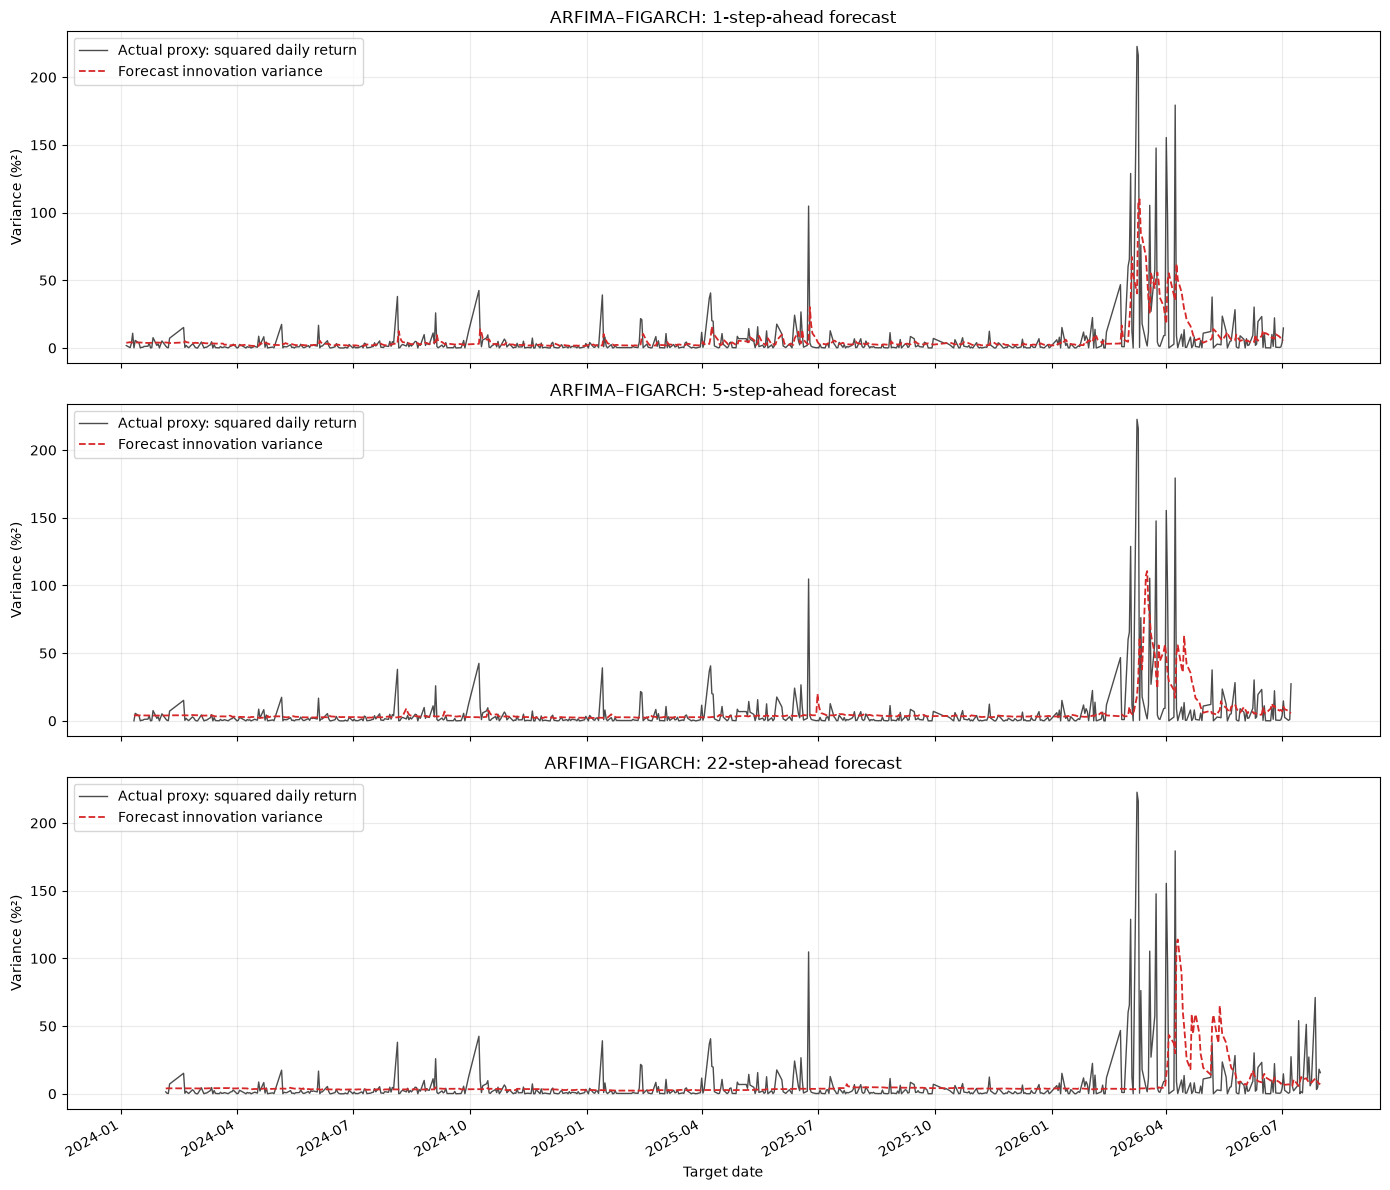

In [25]:
import matplotlib.pyplot as plt

# 选择要画的模型 ARFIMA-GARCH(1,1)
result = forecast_table_arfima_garch

horizons = sorted(result["horizon"].unique())

fig, axes = plt.subplots(
    len(horizons), 1,
    figsize=(14, 4 * len(horizons)),
    sharex=True,
    squeeze=False
)

for ax, h in zip(axes[:, 0], horizons):

    plot_data = (
        result.loc[result["horizon"] == h]
        .sort_values("target")
    )

    # 真实值：日收益率平方 proxy
    ax.plot(
        plot_data["target"],
        plot_data["proxy"],
        linestyle="-",
        color="black",
        linewidth=1,
        alpha=0.7,
        label="Actual proxy: squared daily return"
    )

    # 模型预测：创新方差
    ax.plot(
        plot_data["target"],
        plot_data["innovation_variance"],
        linestyle="--",
        color="tab:red",
        linewidth=1.3,
        label="Forecast innovation variance"
    )

    ax.set_title(f"ARFIMA–FIGARCH: {h}-step-ahead forecast")
    ax.set_ylabel("Variance (%²)")
    ax.grid(alpha=0.25)
    ax.legend()

axes[-1, 0].set_xlabel("Target date")

fig.autofmt_xdate()
plt.tight_layout()
plt.show()

### ARFIMA-IGARCH(1,1)

In [32]:
import numpy as np
import pandas as pd

from scipy.signal import lfilter
from scipy.optimize import minimize

from statsmodels.stats.diagnostic import (
    acorr_ljungbox,
    het_arch
)


# ============================================================
# 0. 设置
# ============================================================

DATE_COL = "date"       # 修改；日期已经是索引时设为 None
PRICE_COL = "close"     # 修改为你的价格列名

DATA_START = "2023-01-01"
DATA_END = "2026-07-31"

WINDOW = 244
HORIZONS = (1, 5, 22)

FORECAST_START = None   # 或 "2024-01-01"

AR_ORDERS = (0, 1, 2)
MA_ORDERS = (0, 1, 2)

BURN = 10

# 初次检查可设为 3，正式运行改为 None
MAX_ORIGINS = None

In [33]:
# ============================================================
# 1. 分数差分系数
# ============================================================

def fractional_weights(xi, length):
    weights = np.empty(length)
    weights[0] = 1.0

    for k in range(1, length):
        weights[k] = (
            weights[k - 1] * (k - 1 - xi) / k
        )

    return weights

In [34]:
# ============================================================
# 2. AR/MA 参数化：保证 AR 平稳、MA 可逆
# ============================================================

def ar_coefficients(partial_parameters):
    k = np.asarray(partial_parameters, dtype=float)

    if len(k) == 0:
        return np.empty(0)

    if len(k) == 1:
        return np.array([k[0]])

    if len(k) == 2:
        return np.array([
            k[0] * (1.0 - k[1]),
            k[1]
        ])

    raise ValueError("这里只支持 0、1、2 阶。")

In [35]:
# ============================================================
# 3. 联合估计固定阶数 ARFIMA(n,xi,s)-IGARCH(1,1)
# ============================================================

def fit_arfima_igarch(returns, n, s, burn=BURN):
    """
    联合条件高斯最大似然。

    独立估计：
        mu, xi, AR系数, MA系数, omega, alpha

    约束：
        beta = 1 - alpha

    窗口以前的中心化收益率和创新设为零。
    首个条件方差取窗口内收益率样本方差。
    """
    y_original = np.asarray(returns, dtype=float)

    if (
        len(y_original) <= burn + 20
        or not np.isfinite(y_original).all()
    ):
        raise ValueError("训练数据不足或含非有限值。")

    scale = np.std(y_original, ddof=0)

    if not np.isfinite(scale) or scale <= 1e-12:
        raise ValueError("收益率没有足够变化。")

    y = y_original / scale
    initial_variance = np.var(y)

    def unpack(params):
        mu = params[0]
        xi = params[1]

        psi = ar_coefficients(
            params[2:2 + n]
        )

        theta = -ar_coefficients(
            params[2 + n:2 + n + s]
        )

        omega, alpha = params[-2:]
        beta = 1.0 - alpha

        return mu, xi, psi, theta, omega, alpha, beta

    def filter_model(params):
        mu, xi, psi, theta, omega, alpha, beta = unpack(params)

        weights = fractional_weights(xi, len(y))

        fractional_y = np.convolve(
            y - mu,
            weights
        )[:len(y)]

        epsilon = lfilter(
            np.r_[1.0, -psi],
            np.r_[1.0, theta],
            fractional_y
        )

        variance = np.empty(len(y))
        variance[0] = initial_variance

        for t in range(1, len(y)):
            variance[t] = (
                omega
                + alpha * epsilon[t - 1] ** 2
                + beta * variance[t - 1]
            )

        return epsilon, variance

    def negative_loglikelihood(params):
        epsilon, variance = filter_model(params)

        if (
            not np.isfinite(epsilon).all()
            or not np.isfinite(variance).all()
            or np.any(variance <= 0)
        ):
            return 1e100

        terms = (
            np.log(2.0 * np.pi)
            + np.log(variance)
            + epsilon ** 2 / variance
        )

        return 0.5 * np.sum(terms[burn:])

    bounds = (
        [
            (None, None),   # mu
            (-0.49, 0.49)   # xi
        ]
        + [(-0.98, 0.98)] * (n + s)
        + [
            (1e-10, None),  # omega：内部缩放单位
            (0.0, 1.0)      # alpha；beta 自动等于 1-alpha
        ]
    )

    successful_results = []
    messages = []

    # 不同的分数阶、AR/MA系数和alpha初值
    starts = [
        (-0.10, 0.0, 0.05),
        (0.10, 0.20, 0.10),
        (0.0, -0.20, 0.20)
    ]

    for xi0, coefficient0, alpha0 in starts:
        start = np.r_[
            np.mean(y),
            xi0,
            np.full(n + s, coefficient0),
            0.01 * initial_variance,
            alpha0
        ]

        result = minimize(
            negative_loglikelihood,
            x0=start,
            method="SLSQP",
            bounds=bounds,
            options={
                "maxiter": 700,
                "ftol": 1e-7
            }
        )

        messages.append(str(result.message))

        if (
            result.success
            and np.isfinite(result.fun)
            and np.isfinite(result.x).all()
            and result.x[-2] > 0
            and 0 <= result.x[-1] <= 1
        ):
            successful_results.append(result)

    if not successful_results:
        raise RuntimeError(
            f"ARFIMA({n},xi,{s})-IGARCH 联合估计失败："
            + " | ".join(messages)
        )

    best = min(
        successful_results,
        key=lambda result: result.fun
    )

    mu, xi, psi, theta, omega, alpha, beta = unpack(best.x)
    epsilon_scaled, variance_scaled = filter_model(best.x)

    epsilon = epsilon_scaled * scale
    variance = variance_scaled * scale ** 2

    n_likelihood = len(y) - burn

    loglikelihood = (
        -best.fun - n_likelihood * np.log(scale)
    )

    # beta不是独立估计参数，不计入K
    parameter_count = n + s + 4

    aic = (
        -2.0 * loglikelihood
        + 2.0 * parameter_count
    )

    params = {
        "mu": mu * scale,
        "xi": xi,
        "omega": omega * scale ** 2,
        "alpha": alpha,
        "beta": beta
    }

    params.update({
        f"psi_{j + 1}": value
        for j, value in enumerate(psi)
    })

    params.update({
        f"theta_{j + 1}": value
        for j, value in enumerate(theta)
    })

    return {
        "n": n,
        "s": s,
        "params": pd.Series(params),
        "epsilon": epsilon,
        "variance": variance,
        "standardized_residuals": epsilon / np.sqrt(variance),
        "loglikelihood": loglikelihood,
        "AIC": aic,
        "K": parameter_count,
        "n_likelihood": n_likelihood
    }

In [36]:
# ============================================================
# 4. 每个窗口按 AIC 选择 ARFIMA 阶数
# ============================================================

def select_arfima_igarch(returns):
    successful_fits = []
    search_rows = []

    for n in AR_ORDERS:
        for s in MA_ORDERS:

            try:
                fit = fit_arfima_igarch(
                    returns,
                    n=n,
                    s=s
                )

            except (RuntimeError, ValueError) as error:
                search_rows.append({
                    "n": n,
                    "s": s,
                    "AIC": np.nan,
                    "success": False,
                    "reason": str(error)
                })

            else:
                successful_fits.append(fit)

                search_rows.append({
                    "n": n,
                    "s": s,
                    "AIC": fit["AIC"],
                    "success": True,
                    "reason": ""
                })

    search_table = pd.DataFrame(search_rows)

    best_fit = (
        min(successful_fits, key=lambda fit: fit["AIC"])
        if successful_fits
        else None
    )

    return best_fit, search_table

In [37]:
# ============================================================
# 5. IGARCH 多步创新方差预测
# ============================================================

def forecast_igarch_variance(fit, horizon):
    params = fit["params"]

    omega = params["omega"]
    alpha = params["alpha"]
    beta = params["beta"]

    first_forecast = (
        omega
        + alpha * fit["epsilon"][-1] ** 2
        + beta * fit["variance"][-1]
    )

    # 第 h 步 = 第 1 步 + (h-1)*omega
    return (
        first_forecast
        + omega * np.arange(horizon)
    )

In [38]:
# ============================================================
# 6. 从 SC 的日价格计算收益率
# ============================================================

data = SC.copy()

if DATE_COL is None:
    data.index = pd.to_datetime(
        data.index,
        errors="raise"
    )
else:
    data[DATE_COL] = pd.to_datetime(
        data[DATE_COL],
        errors="raise"
    )
    data = data.set_index(DATE_COL)

data = data.sort_index()
data = data.loc[DATA_START:DATA_END]

if data.index.has_duplicates:
    raise ValueError("交易日期存在重复，请先处理。")

price = pd.to_numeric(
    data[PRICE_COL],
    errors="raise"
).astype(float)

if (
    not np.isfinite(price.to_numpy()).all()
    or (price <= 0).any()
):
    raise ValueError("价格存在缺失值、无穷值或非正值。")

r = (
    100.0 * (np.log(price) - np.log(price.shift(1)))
).iloc[1:]

r.name = "return_pct"

max_horizon = max(HORIZONS)

if len(r) < WINDOW + max_horizon:
    raise ValueError("数据不足以训练并评价全部预测期限。")

print("收益率观测数：", len(r))
print("收益率起止日期：", r.index[0], "至", r.index[-1])

收益率观测数： 865
,收益率起止日期： 2023-01-04 00:00:00 至 2026-07-31 00:00:00


In [39]:
# ============================================================
# 7. 244 日滚动选阶、联合估计、预测
# ============================================================

forecast_start = (
    None
    if FORECAST_START is None
    else pd.Timestamp(FORECAST_START)
)

origins = [
    t
    for t in range(WINDOW - 1, len(r) - max_horizon)
    if (
        forecast_start is None
        or r.index[t] >= forecast_start
    )
]

if MAX_ORIGINS is not None:
    origins = origins[:MAX_ORIGINS]

if not origins:
    raise ValueError("没有符合条件的预测起点。")

prediction_rows = []
parameter_rows = []
search_tables = []
failure_rows = []

first_best_fit_igarch = None

for number, t in enumerate(origins, start=1):

    train = r.iloc[t - WINDOW + 1:t + 1]

    best_fit, search = select_arfima_igarch(train)

    # 包括整个窗口全部失败时的九组候选记录
    search["origin"] = r.index[t]
    search_tables.append(search)

    if best_fit is None:
        failure_rows.append({
            "origin": r.index[t],
            "reason": "九组候选模型全部估计失败"
        })

    else:
        if first_best_fit_igarch is None:
            first_best_fit_igarch = best_fit

        forecasts = forecast_igarch_variance(
            best_fit,
            horizon=max_horizon
        )

        parameter_rows.append({
            "origin": r.index[t],
            "train_start": train.index[0],
            "train_end": train.index[-1],
            "n_train": len(train),
            "n_best": best_fit["n"],
            "s_best": best_fit["s"],
            "AIC": best_fit["AIC"],
            "loglikelihood": best_fit["loglikelihood"],
            **best_fit["params"].to_dict()
        })

        for h in HORIZONS:
            actual_return = float(r.iloc[t + h])

            prediction_rows.append({
                "origin": r.index[t],
                "target": r.index[t + h],
                "horizon": h,
                "n_best": best_fit["n"],
                "s_best": best_fit["s"],
                "innovation_variance": float(forecasts[h - 1]),
                "actual_return": actual_return,
                "proxy": actual_return ** 2
            })

    if number % 10 == 0 or number == len(origins):
        print(
            f"已完成 {number}/{len(origins)} 个预测起点；"
            f"全部候选失败的起点数：{len(failure_rows)}"
        )

已完成 10/600 个预测起点；全部候选失败的起点数：0
,已完成 20/600 个预测起点；全部候选失败的起点数：0
,已完成 30/600 个预测起点；全部候选失败的起点数：0
,已完成 40/600 个预测起点；全部候选失败的起点数：0
,已完成 50/600 个预测起点；全部候选失败的起点数：0
,已完成 60/600 个预测起点；全部候选失败的起点数：0
,已完成 70/600 个预测起点；全部候选失败的起点数：0
,已完成 80/600 个预测起点；全部候选失败的起点数：0
,已完成 90/600 个预测起点；全部候选失败的起点数：0
,已完成 100/600 个预测起点；全部候选失败的起点数：0
,已完成 110/600 个预测起点；全部候选失败的起点数：0
,已完成 120/600 个预测起点；全部候选失败的起点数：0
,已完成 130/600 个预测起点；全部候选失败的起点数：0
,已完成 140/600 个预测起点；全部候选失败的起点数：0
,已完成 150/600 个预测起点；全部候选失败的起点数：0
,已完成 160/600 个预测起点；全部候选失败的起点数：0
,已完成 170/600 个预测起点；全部候选失败的起点数：0
,已完成 180/600 个预测起点；全部候选失败的起点数：0
,已完成 190/600 个预测起点；全部候选失败的起点数：0
,已完成 200/600 个预测起点；全部候选失败的起点数：0
,已完成 210/600 个预测起点；全部候选失败的起点数：0
,已完成 220/600 个预测起点；全部候选失败的起点数：0
,已完成 230/600 个预测起点；全部候选失败的起点数：0
,已完成 240/600 个预测起点；全部候选失败的起点数：0
,已完成 250/600 个预测起点；全部候选失败的起点数：0
,已完成 260/600 个预测起点；全部候选失败的起点数：0
,已完成 270/600 个预测起点；全部候选失败的起点数：0
,已完成 280/600 个预测起点；全部候选失败的起点数：0
,已完成 290/600 个预测起点；全部候选失败的起点数：0
,已完成 300/600 个预测起点；全部候选失败的起点数：0
,已完成 310/600 个预测起点；全部候选失败的起点数：0
,已完成 320/600 个预测起点

In [40]:
# ============================================================
# 8. 整理结果与样本外评价
# ============================================================

# 使用不同变量名，保留前一个模型的结果
forecast_table_igarch = pd.DataFrame(prediction_rows)
parameter_table_igarch = pd.DataFrame(parameter_rows)

failure_table_igarch = pd.DataFrame(
    failure_rows,
    columns=["origin", "reason"]
)

order_search_table_igarch = pd.concat(
    search_tables,
    ignore_index=True
)

if forecast_table_igarch.empty:
    raise RuntimeError(
        "没有有效预测，请查看 order_search_table_igarch。"
    )

forecast_table_igarch["error"] = (
    forecast_table_igarch["innovation_variance"]
    - forecast_table_igarch["proxy"]
)

forecast_table_igarch["squared_error"] = (
    forecast_table_igarch["error"] ** 2
)

forecast_table_igarch["absolute_error"] = (
    forecast_table_igarch["error"].abs()
)

evaluation_igarch = (
    forecast_table_igarch
    .groupby("horizon")
    .agg(
        N=("error", "size"),
        MSE=("squared_error", "mean"),
        MAE=("absolute_error", "mean")
    )
)

parameter_table_igarch["persistence"] = (
    parameter_table_igarch["alpha"]
    + parameter_table_igarch["beta"]
)

print("\nARFIMA–IGARCH：样本外评价")
print(evaluation_igarch)

print("\n选中阶数的次数：")
print(
    parameter_table_igarch
    .groupby(["n_best", "s_best"])
    .size()
    .rename("count")
)

print("\n第一个成功窗口的参数：")
print(parameter_table_igarch.iloc[0])

print("\n候选模型估计失败次数：")
print((~order_search_table_igarch["success"]).sum())

print("\n全部候选失败的窗口数：")
print(len(failure_table_igarch))

print("\n预测结果前六行：")
print(forecast_table_igarch.head(6))


,ARFIMA–IGARCH：样本外评价
,           N         MSE        MAE
,horizon                            
,1        600  340.080270   7.340023
,5        600  409.824395   8.188863
,22       600  575.990987  11.749206
,
,选中阶数的次数：
,n_best  s_best
,0       0         242
,        1           9
,        2           6
,1       0          77
,        1         104
,2       0          31
,        2         131
,Name: count, dtype: int64
,
,第一个成功窗口的参数：
,origin           2024-01-04 00:00:00
,train_start      2023-01-04 00:00:00
,train_end        2024-01-04 00:00:00
,n_train                          244
,n_best                             2
,s_best                             2
,AIC                      1021.786586
,loglikelihood            -502.893293
,mu                          0.011279
,xi                         -0.011495
,omega                            0.0
,alpha                            0.0
,beta                             1.0
,psi_1                       0.000687
,psi_2                      -0

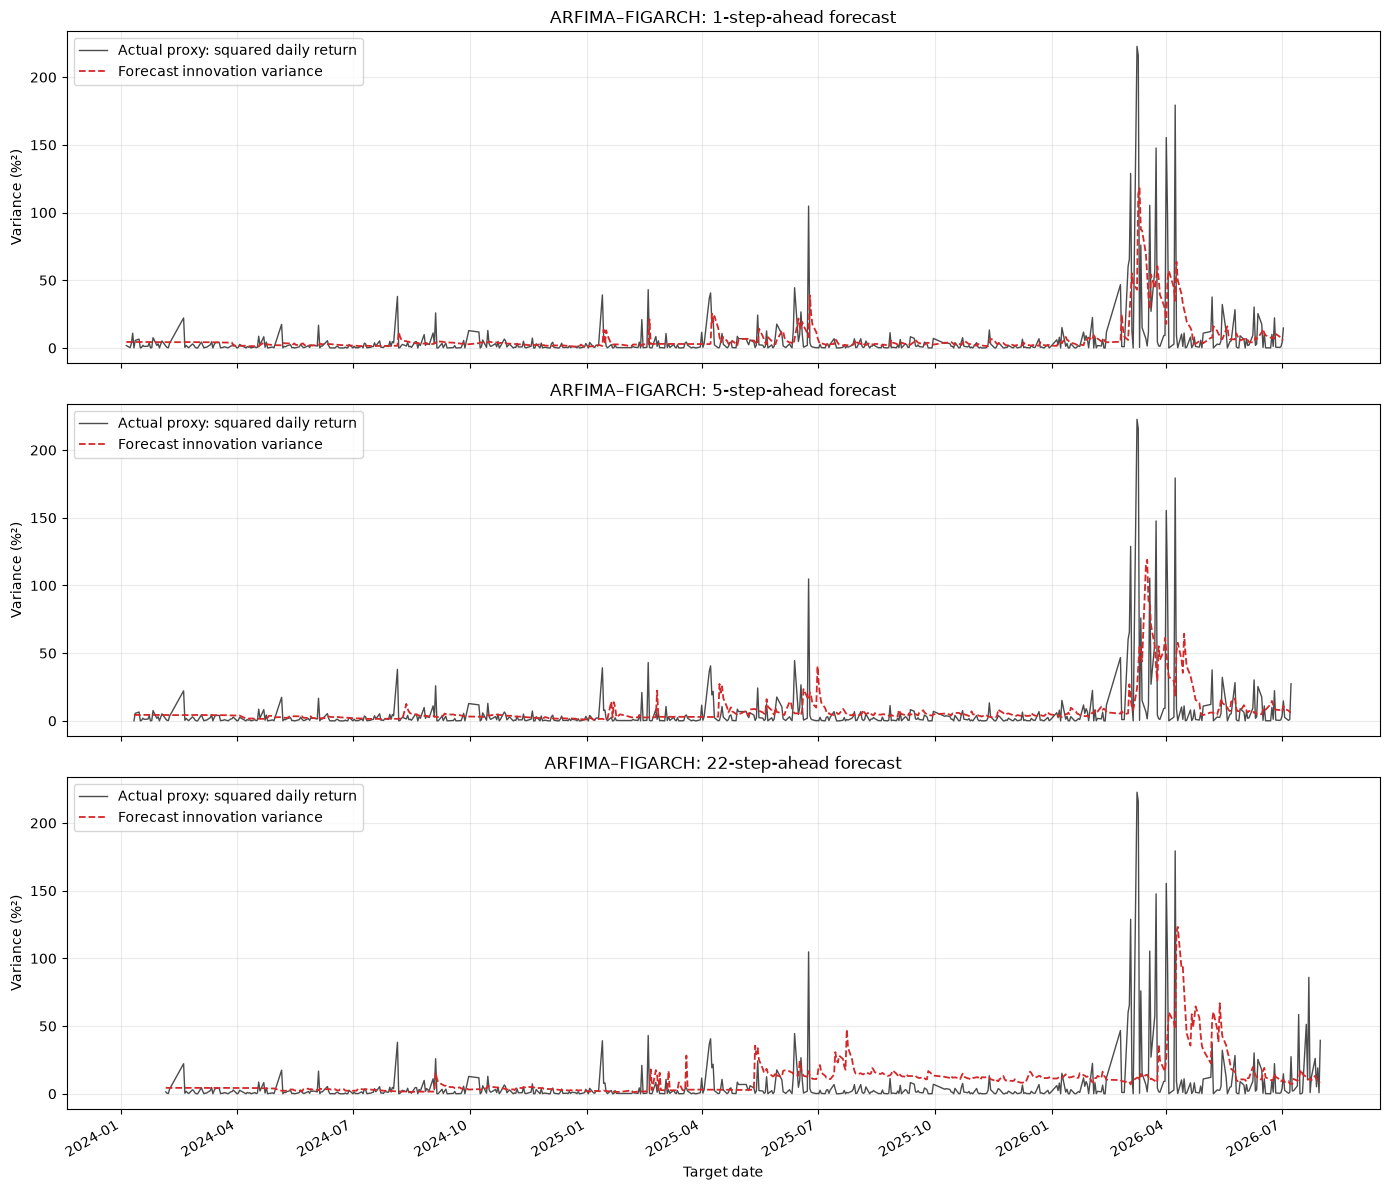

In [64]:
import matplotlib.pyplot as plt

# 选择要画的模型 ARFIMA-GARCH(1,1)
result = forecast_table_igarch

horizons = sorted(result["horizon"].unique())

fig, axes = plt.subplots(
    len(horizons), 1,
    figsize=(14, 4 * len(horizons)),
    sharex=True,
    squeeze=False
)

for ax, h in zip(axes[:, 0], horizons):

    plot_data = (
        result.loc[result["horizon"] == h]
        .sort_values("target")
    )

    # 真实值：日收益率平方 proxy
    ax.plot(
        plot_data["target"],
        plot_data["proxy"],
        linestyle="-",
        color="black",
        linewidth=1,
        alpha=0.7,
        label="Actual proxy: squared daily return"
    )

    # 模型预测：创新方差
    ax.plot(
        plot_data["target"],
        plot_data["innovation_variance"],
        linestyle="--",
        color="tab:red",
        linewidth=1.3,
        label="Forecast innovation variance"
    )

    ax.set_title(f"ARFIMA–FIGARCH: {h}-step-ahead forecast")
    ax.set_ylabel("Variance (%²)")
    ax.grid(alpha=0.25)
    ax.legend()

axes[-1, 0].set_xlabel("Target date")

fig.autofmt_xdate()
plt.tight_layout()
plt.show()

### ARFIMA-FIGARCH

In [43]:
import numpy as np
import pandas as pd

from scipy.signal import lfilter
from scipy.optimize import minimize

# ============================================================
# 0. 设置
# ============================================================

DATE_COL = "date"       # 修改；日期已是索引时设为 None
PRICE_COL = "close"     # 修改为你的价格列名

DATA_START = "2023-01-01"
DATA_END = "2026-07-31"

WINDOW = 244
HORIZONS = (1, 5, 22)

FORECAST_START = None   # 或 "2024-01-01"

AR_ORDERS = (0, 1, 2)
MA_ORDERS = (0, 1, 2)

BURN = 10
FIGARCH_TRUNCATION = 1000

# 初次检查可设为 3；正式运行改为 None
MAX_ORIGINS = None

In [44]:
# ============================================================
# 1. 均值部分的分数差分系数与 AR/MA 参数化
# ============================================================

def fractional_weights(xi, length):
    weights = np.empty(length)
    weights[0] = 1.0

    for k in range(1, length):
        weights[k] = (
            weights[k - 1] * (k - 1 - xi) / k
        )

    return weights


def ar_coefficients(partial_parameters):
    k = np.asarray(partial_parameters, dtype=float)

    if len(k) == 0:
        return np.empty(0)

    if len(k) == 1:
        return np.array([k[0]])

    if len(k) == 2:
        return np.array([
            k[0] * (1.0 - k[1]),
            k[1]
        ])

    raise ValueError("这里只支持 0、1、2 阶。")

In [45]:
# ============================================================
# 2. FIGARCH(1,d,1) 的 ARCH 权重
# ============================================================

def figarch_weights(d, phi, beta, truncation):
    """
    数组第 0 项对应滞后 1。

    delta_1 = d
    lambda_1 = d + phi - beta

    delta_k = (k-1-d)/k * delta_{k-1}
    lambda_k = beta*lambda_{k-1}
               + delta_k - phi*delta_{k-1}
    """
    delta = np.empty(truncation)
    weights = np.empty(truncation)

    delta[0] = d
    weights[0] = d + phi - beta

    for j in range(1, truncation):
        k = j + 1

        delta[j] = (
            delta[j - 1] * (k - 1 - d) / k
        )

        weights[j] = (
            beta * weights[j - 1]
            + delta[j]
            - phi * delta[j - 1]
        )

    return weights


def figarch_variances(epsilon, weights, constant, backcast):
    """
    h_t = constant + sum_{k=1}^M lambda_k*epsilon_{t-k}^2

    窗口以前的 epsilon^2 用 backcast 补齐。
    """
    n_obs = len(epsilon)

    # prefix[t] = 前 t 个权重之和
    prefix = np.r_[0.0, np.cumsum(weights)]
    total_weight = prefix[-1]

    # 已经观察到的历史平方创新贡献
    observed = np.zeros(n_obs)

    if n_obs > 1:
        observed[1:] = np.convolve(
            epsilon ** 2,
            weights[:n_obs]
        )[:n_obs - 1]

    # 第 t 个观测之前可用的历史创新数量为 t
    available = np.minimum(
        np.arange(n_obs),
        len(weights)
    )

    missing_weight = total_weight - prefix[available]

    return (
        constant
        + observed
        + backcast * missing_weight
    )

In [47]:
# ============================================================
# 3. 联合估计固定阶数 ARFIMA(n,xi,s)-FIGARCH(1,d,1)
# ============================================================

def fit_arfima_figarch(
    returns,
    n,
    s,
    burn=BURN,
    truncation=FIGARCH_TRUNCATION
):
    """
    联合条件高斯最大似然。

    参数：
        mu, xi, AR系数, MA系数,
        omega, d, phi, beta

    内部通过 u_phi、u_beta 参数化约束：
        phi = (1-d)/2 * u_phi
        beta = (d+phi) * u_beta

    均值初始化：
        窗口以前的中心化收益率、创新设为零。

    方差初始化：
        窗口以前的平方创新用窗口收益率方差补齐。
    """
    y_original = np.asarray(returns, dtype=float)

    if (
        len(y_original) <= burn + 20
        or not np.isfinite(y_original).all()
    ):
        raise ValueError("训练数据不足或含非有限值。")

    scale = np.std(y_original, ddof=0)

    if not np.isfinite(scale) or scale <= 1e-12:
        raise ValueError("收益率没有足够变化。")

    y = y_original / scale

    # 仅由当前训练窗口计算
    backcast_scaled = np.var(y, ddof=0)

    def unpack(params):
        mu = params[0]
        xi = params[1]

        psi = ar_coefficients(
            params[2:2 + n]
        )

        theta = -ar_coefficients(
            params[2 + n:2 + n + s]
        )

        omega, d, u_phi, u_beta = params[-4:]

        phi = 0.5 * (1.0 - d) * u_phi
        beta = (d + phi) * u_beta

        return mu, xi, psi, theta, omega, d, phi, beta

    def filter_model(params):
        (
            mu, xi, psi, theta,
            omega, d, phi, beta
        ) = unpack(params)

        mean_weights = fractional_weights(xi, len(y))

        fractional_y = np.convolve(
            y - mu,
            mean_weights
        )[:len(y)]

        epsilon = lfilter(
            np.r_[1.0, -psi],
            np.r_[1.0, theta],
            fractional_y
        )

        variance_weights = figarch_weights(
            d=d,
            phi=phi,
            beta=beta,
            truncation=truncation
        )

        constant = omega / (1.0 - beta)

        variance = figarch_variances(
            epsilon=epsilon,
            weights=variance_weights,
            constant=constant,
            backcast=backcast_scaled
        )

        return epsilon, variance, variance_weights

    def negative_loglikelihood(params):
        epsilon, variance, weights = filter_model(params)

        if (
            not np.isfinite(epsilon).all()
            or not np.isfinite(variance).all()
            or not np.isfinite(weights).all()
            or np.any(variance <= 0)
            or np.min(weights) < -1e-12
        ):
            return 1e100

        terms = (
            np.log(2.0 * np.pi)
            + np.log(variance)
            + epsilon ** 2 / variance
        )

        return 0.5 * np.sum(terms[burn:])

    bounds = (
        [
            (None, None),   # mu
            (-0.49, 0.49)   # xi
        ]
        + [(-0.98, 0.98)] * (n + s)
        + [
            (1e-10, None),  # omega
            (0.001, 0.999), # d：避免精确端点
            (0.0, 1.0),     # u_phi
            (0.0, 0.999)    # u_beta
        ]
    )

    successful_results = []
    messages = []

    # xi、AR/MA初值、d、u_phi、u_beta
    starts = [
        (-0.10, 0.0, 0.20, 0.40, 0.60),
        (0.10, 0.20, 0.40, 0.60, 0.80),
        (0.0, -0.20, 0.70, 0.40, 0.60)
    ]

    for xi0, coefficient0, d0, uphi0, ubeta0 in starts:
        start = np.r_[
            np.mean(y),
            xi0,
            np.full(n + s, coefficient0),
            0.05 * backcast_scaled,
            d0,
            uphi0,
            ubeta0
        ]

        result = minimize(
            negative_loglikelihood,
            x0=start,
            method="SLSQP",
            bounds=bounds,
            options={
                "maxiter": 700,
                "ftol": 1e-7
            }
        )

        messages.append(str(result.message))

        if (
            result.success
            and np.isfinite(result.fun)
            and result.fun < 1e99
            and np.isfinite(result.x).all()
        ):
            successful_results.append(result)

    if not successful_results:
        raise RuntimeError(
            f"ARFIMA({n},xi,{s})-FIGARCH 联合估计失败："
            + " | ".join(messages)
        )

    best = min(
        successful_results,
        key=lambda result: result.fun
    )

    (
        mu, xi, psi, theta,
        omega, d, phi, beta
    ) = unpack(best.x)

    epsilon_scaled, variance_scaled, weights = filter_model(
        best.x
    )

    # 恢复为百分比收益率单位
    epsilon = epsilon_scaled * scale
    variance = variance_scaled * scale ** 2
    backcast = backcast_scaled * scale ** 2
    omega_original = omega * scale ** 2

    n_likelihood = len(y) - burn

    loglikelihood = (
        -best.fun - n_likelihood * np.log(scale)
    )

    # mu, xi, omega, d, phi, beta + AR/MA系数
    parameter_count = n + s + 6

    aic = (
        -2.0 * loglikelihood
        + 2.0 * parameter_count
    )

    params = {
        "mu": mu * scale,
        "xi": xi,
        "omega": omega_original,
        "d": d,
        "phi": phi,
        "beta": beta
    }

    params.update({
        f"psi_{j + 1}": value
        for j, value in enumerate(psi)
    })

    params.update({
        f"theta_{j + 1}": value
        for j, value in enumerate(theta)
    })

    return {
        "n": n,
        "s": s,
        "params": pd.Series(params),
        "epsilon": epsilon,
        "variance": variance,
        "weights": weights,
        "constant": omega_original / (1.0 - beta),
        "backcast": backcast,
        "loglikelihood": loglikelihood,
        "AIC": aic,
        "K": parameter_count,
        "n_likelihood": n_likelihood
    }

In [48]:
# ============================================================
# 4. 每个窗口按 AIC 选择 ARFIMA 阶数
# ============================================================

def select_arfima_figarch(returns):
    successful_fits = []
    search_rows = []

    for n in AR_ORDERS:
        for s in MA_ORDERS:

            try:
                fit = fit_arfima_figarch(
                    returns,
                    n=n,
                    s=s
                )

            except (RuntimeError, ValueError) as error:
                search_rows.append({
                    "n": n,
                    "s": s,
                    "AIC": np.nan,
                    "success": False,
                    "reason": str(error)
                })

            else:
                successful_fits.append(fit)

                search_rows.append({
                    "n": n,
                    "s": s,
                    "AIC": fit["AIC"],
                    "success": True,
                    "reason": ""
                })

    search_table = pd.DataFrame(search_rows)

    best_fit = (
        min(successful_fits, key=lambda fit: fit["AIC"])
        if successful_fits
        else None
    )

    return best_fit, search_table

In [49]:
# ============================================================
# 5. FIGARCH 多步创新方差预测
# ============================================================

def forecast_figarch_variance(fit, horizon):
    """
    未来未知的 epsilon^2，用对应预测方差替代。
    窗口以前的 epsilon^2，继续使用同一个 backcast。
    """
    weights = fit["weights"]
    constant = fit["constant"]
    backcast = fit["backcast"]

    prefix = np.r_[0.0, np.cumsum(weights)]
    total_weight = prefix[-1]

    n_obs = len(fit["epsilon"])

    squared_innovations = np.empty(n_obs + horizon)
    squared_innovations[:n_obs] = fit["epsilon"] ** 2

    forecasts = np.empty(horizon)

    for j in range(horizon):
        position = n_obs + j
        available = min(position, len(weights))

        # 从最近的平方创新往前排列
        history = squared_innovations[
            position - available:position
        ][::-1]

        observed_contribution = np.dot(
            weights[:available],
            history
        )

        missing_weight = (
            total_weight - prefix[available]
        )

        forecasts[j] = (
            constant
            + observed_contribution
            + backcast * missing_weight
        )

        # E_t[epsilon_future^2] = 预测的创新方差
        squared_innovations[position] = forecasts[j]

    return forecasts

In [50]:
# ============================================================
# 6. 从 SC 日价格计算百分比对数收益率
# ============================================================

data = SC.copy()

if DATE_COL is None:
    data.index = pd.to_datetime(
        data.index,
        errors="raise"
    )
else:
    data[DATE_COL] = pd.to_datetime(
        data[DATE_COL],
        errors="raise"
    )
    data = data.set_index(DATE_COL)

data = data.sort_index()
data = data.loc[DATA_START:DATA_END]

if data.index.has_duplicates:
    raise ValueError("交易日期存在重复，请先处理。")

price = pd.to_numeric(
    data[PRICE_COL],
    errors="raise"
).astype(float)

if (
    not np.isfinite(price.to_numpy()).all()
    or (price <= 0).any()
):
    raise ValueError("价格存在缺失值、无穷值或非正值。")

r = (
    100.0 * (np.log(price) - np.log(price.shift(1)))
).iloc[1:]

r.name = "return_pct"

max_horizon = max(HORIZONS)

if len(r) < WINDOW + max_horizon:
    raise ValueError("数据不足以训练并评价全部预测期限。")

print("收益率观测数：", len(r))
print("收益率起止日期：", r.index[0], "至", r.index[-1])

收益率观测数： 865
,收益率起止日期： 2023-01-04 00:00:00 至 2026-07-31 00:00:00


In [51]:
# ============================================================
# 7. 244 日滚动选阶、联合估计、预测
# ============================================================

forecast_start = (
    None
    if FORECAST_START is None
    else pd.Timestamp(FORECAST_START)
)

origins = [
    t
    for t in range(WINDOW - 1, len(r) - max_horizon)
    if (
        forecast_start is None
        or r.index[t] >= forecast_start
    )
]

if MAX_ORIGINS is not None:
    origins = origins[:MAX_ORIGINS]

if not origins:
    raise ValueError("没有符合条件的预测起点。")

prediction_rows = []
parameter_rows = []
search_tables = []
failure_rows = []

for number, t in enumerate(origins, start=1):

    train = r.iloc[t - WINDOW + 1:t + 1]

    best_fit, search = select_arfima_figarch(train)

    search["origin"] = r.index[t]
    search_tables.append(search)

    if best_fit is None:
        failure_rows.append({
            "origin": r.index[t],
            "reason": "九组候选模型全部估计失败"
        })

    else:
        forecasts = forecast_figarch_variance(
            best_fit,
            horizon=max_horizon
        )

        parameter_rows.append({
            "origin": r.index[t],
            "train_start": train.index[0],
            "train_end": train.index[-1],
            "n_train": len(train),
            "n_best": best_fit["n"],
            "s_best": best_fit["s"],
            "AIC": best_fit["AIC"],
            "loglikelihood": best_fit["loglikelihood"],
            "backcast": best_fit["backcast"],
            "weight_sum": best_fit["weights"].sum(),
            **best_fit["params"].to_dict()
        })

        for h in HORIZONS:
            actual_return = float(r.iloc[t + h])

            prediction_rows.append({
                "origin": r.index[t],
                "target": r.index[t + h],
                "horizon": h,
                "n_best": best_fit["n"],
                "s_best": best_fit["s"],
                "innovation_variance": float(forecasts[h - 1]),
                "actual_return": actual_return,
                "proxy": actual_return ** 2
            })

    if number % 10 == 0 or number == len(origins):
        print(
            f"已完成 {number}/{len(origins)} 个预测起点；"
            f"全部候选失败的起点数：{len(failure_rows)}"
        )

已完成 10/600 个预测起点；全部候选失败的起点数：0
,已完成 20/600 个预测起点；全部候选失败的起点数：0
,已完成 30/600 个预测起点；全部候选失败的起点数：0
,已完成 40/600 个预测起点；全部候选失败的起点数：0
,已完成 50/600 个预测起点；全部候选失败的起点数：0
,已完成 60/600 个预测起点；全部候选失败的起点数：0
,已完成 70/600 个预测起点；全部候选失败的起点数：0
,已完成 80/600 个预测起点；全部候选失败的起点数：0
,已完成 90/600 个预测起点；全部候选失败的起点数：0
,已完成 100/600 个预测起点；全部候选失败的起点数：0
,已完成 110/600 个预测起点；全部候选失败的起点数：0
,已完成 120/600 个预测起点；全部候选失败的起点数：0
,已完成 130/600 个预测起点；全部候选失败的起点数：0
,已完成 140/600 个预测起点；全部候选失败的起点数：0
,已完成 150/600 个预测起点；全部候选失败的起点数：0
,已完成 160/600 个预测起点；全部候选失败的起点数：0
,已完成 170/600 个预测起点；全部候选失败的起点数：0
,已完成 180/600 个预测起点；全部候选失败的起点数：0
,已完成 190/600 个预测起点；全部候选失败的起点数：0
,已完成 200/600 个预测起点；全部候选失败的起点数：0
,已完成 210/600 个预测起点；全部候选失败的起点数：0
,已完成 220/600 个预测起点；全部候选失败的起点数：0
,已完成 230/600 个预测起点；全部候选失败的起点数：0
,已完成 240/600 个预测起点；全部候选失败的起点数：0
,已完成 250/600 个预测起点；全部候选失败的起点数：0
,已完成 260/600 个预测起点；全部候选失败的起点数：0
,已完成 270/600 个预测起点；全部候选失败的起点数：0
,已完成 280/600 个预测起点；全部候选失败的起点数：0
,已完成 290/600 个预测起点；全部候选失败的起点数：0
,已完成 300/600 个预测起点；全部候选失败的起点数：0
,已完成 310/600 个预测起点；全部候选失败的起点数：0
,已完成 320/600 个预测起点

In [52]:
# ============================================================
# 8. 整理结果与样本外评价
# ============================================================

forecast_table_figarch = pd.DataFrame(prediction_rows)
parameter_table_figarch = pd.DataFrame(parameter_rows)

failure_table_figarch = pd.DataFrame(
    failure_rows,
    columns=["origin", "reason"]
)

order_search_table_figarch = pd.concat(
    search_tables,
    ignore_index=True
)

if forecast_table_figarch.empty:
    raise RuntimeError(
        "没有有效预测，请查看 order_search_table_figarch。"
    )

forecast_table_figarch["error"] = (
    forecast_table_figarch["innovation_variance"]
    - forecast_table_figarch["proxy"]
)

forecast_table_figarch["squared_error"] = (
    forecast_table_figarch["error"] ** 2
)

forecast_table_figarch["absolute_error"] = (
    forecast_table_figarch["error"].abs()
)

evaluation_figarch = (
    forecast_table_figarch
    .groupby("horizon")
    .agg(
        N=("error", "size"),
        MSE=("squared_error", "mean"),
        MAE=("absolute_error", "mean")
    )
)

print("\nARFIMA–FIGARCH：样本外评价")
print(evaluation_figarch)

print("\n选中阶数的次数：")
print(
    parameter_table_figarch
    .groupby(["n_best", "s_best"])
    .size()
    .rename("count")
)

print("\n第一个成功窗口的参数：")
print(parameter_table_figarch.iloc[0])

print("\n候选模型估计失败次数：")
print((~order_search_table_figarch["success"]).sum())

print("\n全部候选失败的窗口数：")
print(len(failure_table_figarch))

print("\n预测结果前六行：")
print(forecast_table_figarch.head(6))


,ARFIMA–FIGARCH：样本外评价
,           N         MSE       MAE
,horizon                           
,1        600  360.839887  7.255775
,5        600  396.226416  7.627270
,22       600  523.739677  9.048556
,
,选中阶数的次数：
,n_best  s_best
,0       0         202
,        1           9
,        2          33
,1       0          64
,        1         142
,2       0          23
,        2         127
,Name: count, dtype: int64
,
,第一个成功窗口的参数：
,origin           2024-01-04 00:00:00
,train_start      2023-01-04 00:00:00
,train_end        2024-01-04 00:00:00
,n_train                          244
,n_best                             0
,s_best                             0
,AIC                      1025.206493
,loglikelihood            -506.603246
,backcast                    4.472664
,weight_sum                  0.483601
,mu                          0.025612
,xi                         -0.036438
,omega                       2.119617
,d                           0.101364
,phi                              

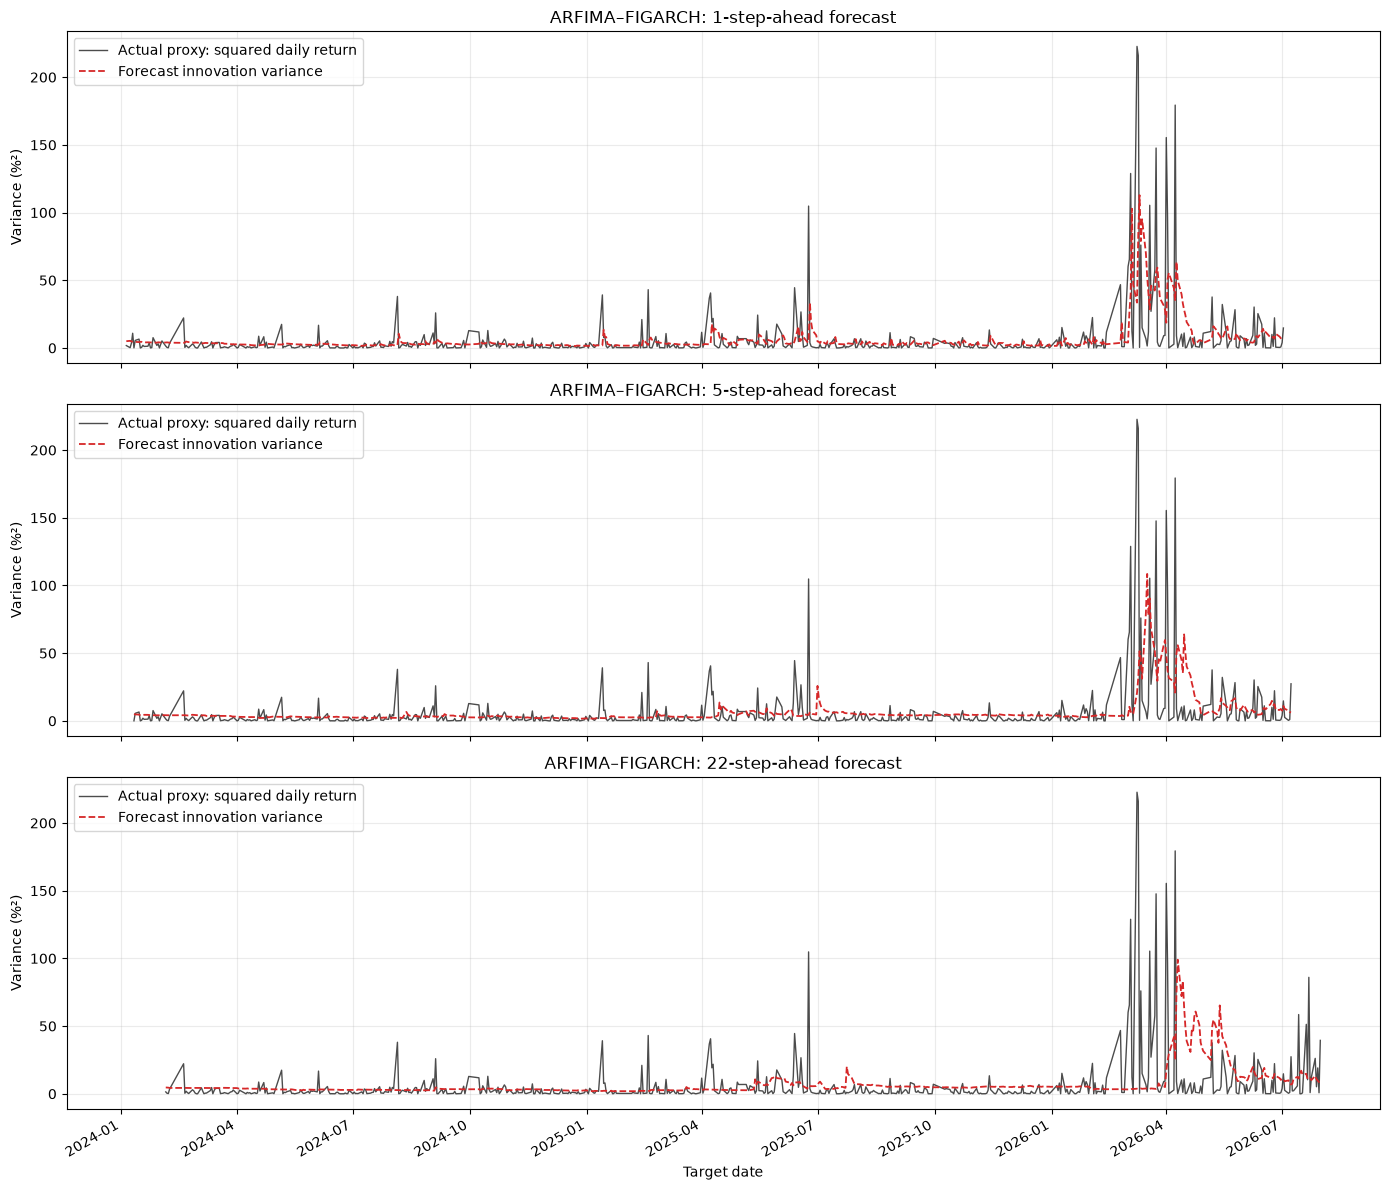

In [53]:
import matplotlib.pyplot as plt

# 选择要画的模型
result = forecast_table_figarch

# 其他模型：
# result = forecast_table_igarch
# result = forecast_table       # 前面 ARIMA 或 ARFIMA–GARCH 的结果

horizons = sorted(result["horizon"].unique())

fig, axes = plt.subplots(
    len(horizons), 1,
    figsize=(14, 4 * len(horizons)),
    sharex=True,
    squeeze=False
)

for ax, h in zip(axes[:, 0], horizons):

    plot_data = (
        result.loc[result["horizon"] == h]
        .sort_values("target")
    )

    # 真实值：日收益率平方 proxy
    ax.plot(
        plot_data["target"],
        plot_data["proxy"],
        linestyle="-",
        color="black",
        linewidth=1,
        alpha=0.7,
        label="Actual proxy: squared daily return"
    )

    # 模型预测：创新方差
    ax.plot(
        plot_data["target"],
        plot_data["innovation_variance"],
        linestyle="--",
        color="tab:red",
        linewidth=1.3,
        label="Forecast innovation variance"
    )

    ax.set_title(f"ARFIMA–FIGARCH: {h}-step-ahead forecast")
    ax.set_ylabel("Variance (%²)")
    ax.grid(alpha=0.25)
    ax.legend()

axes[-1, 0].set_xlabel("Target date")

fig.autofmt_xdate()
plt.tight_layout()
plt.show()

### Random Forest + XGBoost

Fu, T., Huang, D., Feng, L. and Tang, X., 2024. More is better? The impact of predictor choice on the INE oil futures volatility forecasting. Energy Economics, 134, p.107540.

In [57]:
# %pip install scikit-learn
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error


# ============================================================
# 1. 数据整理
# ============================================================

RF_data = SC[["date", "return"]].copy()

RF_data["date"] = pd.to_datetime(RF_data["date"])
RF_data["return"] = pd.to_numeric(RF_data["return"], errors="coerce")

RF_data = (
    RF_data.sort_values("date")
    .reset_index(drop=True)
)

# 不直接删除缺失收益率，避免将不相邻交易日拼接起来
if RF_data["date"].isna().any():
    raise ValueError("date 列存在无效日期。")

if RF_data["date"].duplicated().any():
    raise ValueError("同一天有多条记录，请先确认每天保留哪一个合约。")

if not np.isfinite(RF_data["return"].to_numpy()).all():
    raise ValueError("return 列存在缺失值或无穷值，请先处理。")

# 保留你已有收益率的定义与单位
RF_data["proxy"] = RF_data["return"] ** 2

window = 244
horizons = [1, 5, 22]

if len(RF_data) < window + max(horizons):
    raise ValueError("数据不足，至少需要 244 + 22 个交易日。")

In [58]:
# ============================================================
# 2. 构造特征：所有信息均截至预测日
# ============================================================

def make_RF_features(data):
    X = pd.DataFrame(index=data.index)

    # 今天及过去四天的收益率、平方收益率
    for lag in range(5):
        X[f"return_lag_{lag}"] = data["return"].shift(lag)
        X[f"proxy_lag_{lag}"] = data["proxy"].shift(lag)

    # 历史一周、一个月的平均平方收益率
    for k in [5, 22]:
        X[f"proxy_mean_{k}"] = data["proxy"].rolling(k).mean()
        X[f"return_mean_{k}"] = data["return"].rolling(k).mean()

    return X

In [59]:
# ============================================================
# 3. 244 天窗口，每天滚动，分别预测 h = 1, 5, 22
# ============================================================

RF_results = {}
RF_models = {}       # 每个 horizon 最后一个窗口的模型
RF_importance = {}   # 最后一个窗口的特征重要性

for h in horizons:

    records = []

    # t 为预测起点：假设当天收益率已知
    # t+h 必须位于数据范围内，才能进行样本外评价
    for t in range(window - 1, len(RF_data) - h):

        # 最近 244 天，包含预测起点 t
        sample = RF_data.iloc[t - window + 1:t + 1].copy()
        sample = sample.reset_index(drop=True)

        X = make_RF_features(sample)

        # 对每个历史起点 s：
        # 标签 = s+1 到 s+h 的平均平方收益率
        future_proxy = pd.concat(
            [sample["proxy"].shift(-j) for j in range(1, h + 1)],
            axis=1
        )

        # 必须 h 个未来值全部已知，才保留该训练标签
        y = future_proxy.mean(axis=1)
        y = y.where(future_proxy.notna().all(axis=1))

        train_mask = X.notna().all(axis=1) & y.notna()

        X_train = X.loc[train_mask]
        y_train = y.loc[train_mask]

        # 预测起点当天的特征
        X_test = X.iloc[[-1]]

        model = RandomForestRegressor(
            n_estimators=300,
            max_depth=5,
            min_samples_leaf=5,
            max_features=1.0,
            random_state=2,
            n_jobs=-1
        )

        model.fit(X_train, y_train)

        prediction = model.predict(X_test)[0]

        # 实际未来区间目标：只用于评价，不参与训练
        actual = RF_data["proxy"].iloc[t + 1:t + h + 1].mean()

        records.append({
            "origin_date": RF_data["date"].iloc[t],
            "target_start_date": RF_data["date"].iloc[t + 1],
            "target_end_date": RF_data["date"].iloc[t + h],
            "actual": actual,
            "forecast": prediction,
            "n_train": len(y_train)
        })

    RF_results[h] = pd.DataFrame(records).set_index("origin_date")
    RF_results[h]["error"] = (
        RF_results[h]["actual"] - RF_results[h]["forecast"]
    )

    RF_models[h] = model

    RF_importance[h] = pd.Series(
        model.feature_importances_,
        index=X_train.columns,
        name="importance"
    ).sort_values(ascending=False)

    print(f"h = {h}: 完成 {len(records)} 次滚动预测")

h = 1: 完成 622 次滚动预测
,h = 5: 完成 618 次滚动预测
,h = 22: 完成 601 次滚动预测


In [60]:
# ============================================================
# 4. 输出单独变量，方便后续比较模型
# ============================================================

RF_result_1 = RF_results[1]
RF_result_5 = RF_results[5]
RF_result_22 = RF_results[22]

RF_forecast_1 = RF_result_1["forecast"]
RF_forecast_5 = RF_result_5["forecast"]
RF_forecast_22 = RF_result_22["forecast"]

RF_actual_1 = RF_result_1["actual"]
RF_actual_5 = RF_result_5["actual"]
RF_actual_22 = RF_result_22["actual"]

RF_error_1 = RF_result_1["error"]
RF_error_5 = RF_result_5["error"]
RF_error_22 = RF_result_22["error"]

In [61]:
# ============================================================
# 5. MSE 和 MAE
# ============================================================

RF_metrics = pd.DataFrame(
    {
        h: {
            "MSE": mean_squared_error(
                RF_results[h]["actual"],
                RF_results[h]["forecast"]
            ),
            "MAE": mean_absolute_error(
                RF_results[h]["actual"],
                RF_results[h]["forecast"]
            ),
            "N_forecasts": len(RF_results[h])
        }
        for h in horizons
    }
).T

RF_metrics.index.name = "horizon"

RF_MSE_1 = RF_metrics.loc[1, "MSE"]
RF_MSE_5 = RF_metrics.loc[5, "MSE"]
RF_MSE_22 = RF_metrics.loc[22, "MSE"]

RF_MAE_1 = RF_metrics.loc[1, "MAE"]
RF_MAE_5 = RF_metrics.loc[5, "MAE"]
RF_MAE_22 = RF_metrics.loc[22, "MAE"]

display(RF_metrics)

,MSE,MAE,N_forecasts
horizon,,,
1,3.701543e-06,0.000758,622.0
5,1.179788e-06,0.000449,618.0
22,9.787243e-07,0.000434,601.0


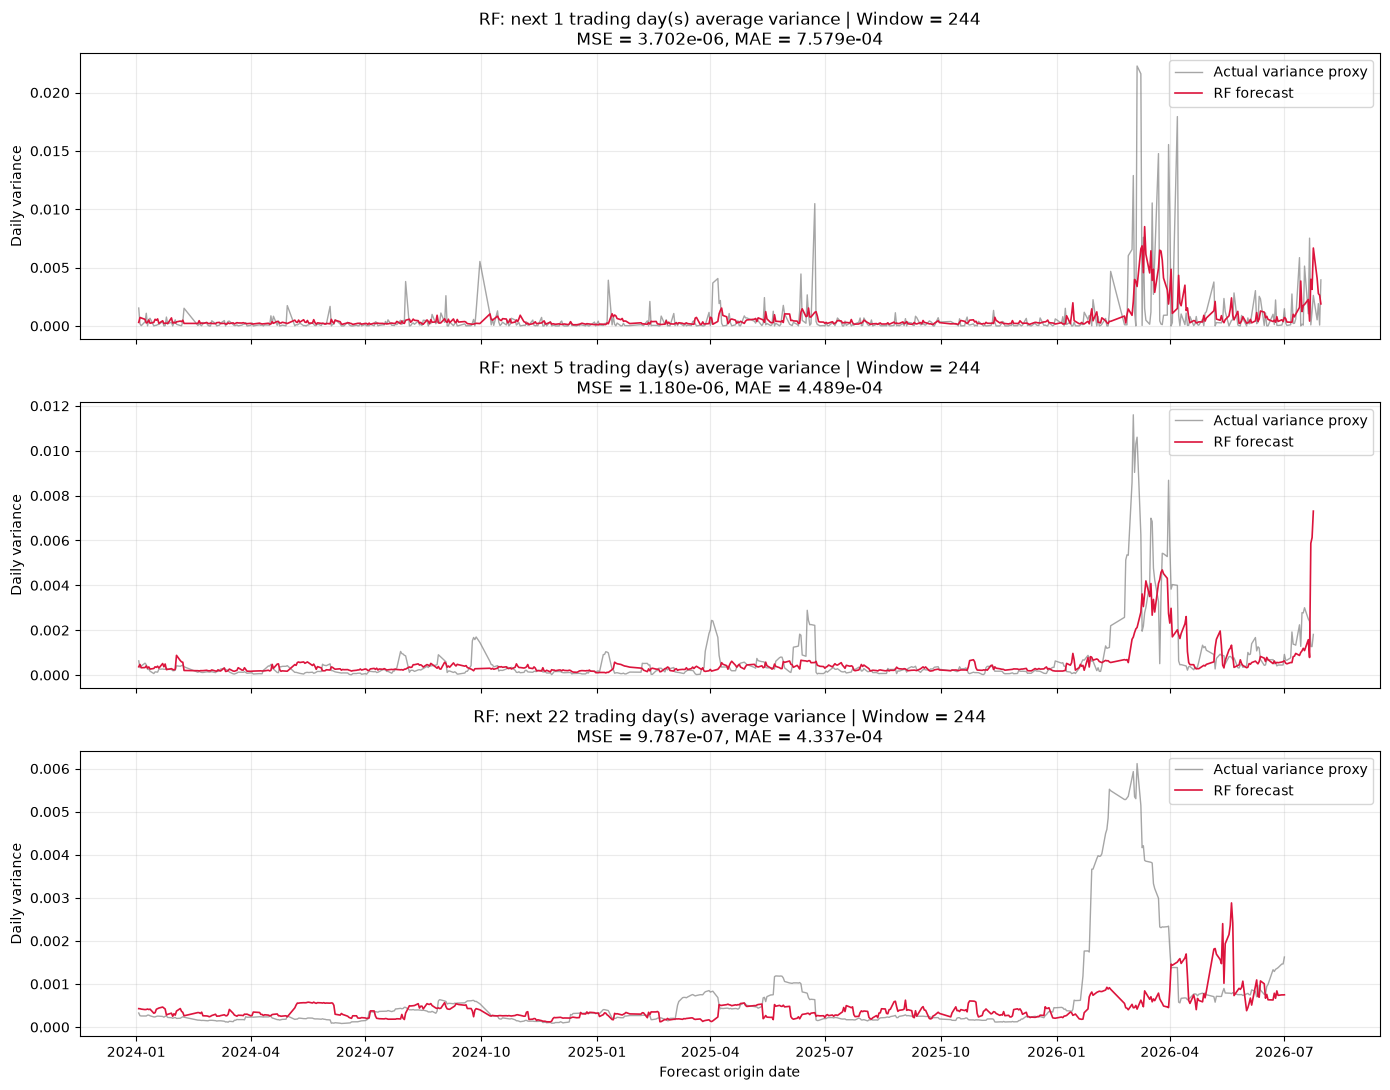

In [62]:
# ============================================================
# 6. 实际值与预测值画图
# ============================================================

fig, axes = plt.subplots(3, 1, figsize=(14, 11), sharex=True)

for ax, h in zip(axes, horizons):

    result = RF_results[h]

    ax.plot(
        result.index,
        result["actual"],
        color="grey",
        alpha=0.7,
        linewidth=1,
        label="Actual variance proxy"
    )

    ax.plot(
        result.index,
        result["forecast"],
        color="crimson",
        linewidth=1.2,
        label="RF forecast"
    )

    ax.set_title(
        f"RF: next {h} trading day(s) average variance | "
        f"Window = {window}\n"
        f"MSE = {RF_metrics.loc[h, 'MSE']:.3e}, "
        f"MAE = {RF_metrics.loc[h, 'MAE']:.3e}"
    )

    ax.set_ylabel("Daily variance")
    ax.grid(alpha=0.25)
    ax.legend()

axes[-1].set_xlabel("Forecast origin date")

plt.tight_layout()
plt.show()

### XGBoost

In [68]:
# %pip install xgboost

from xgboost import XGBRegressor

# 沿用此前已导入的：
# numpy、pandas、matplotlib
# mean_squared_error、mean_absolute_error
# RF_data、make_RF_features

window = 244
horizons = [1, 5, 22]


# ============================================================
# 1. 244 天窗口，每天滚动，分别预测 h = 1, 5, 22
# ============================================================

XGB_results = {}
XGB_models = {}
XGB_importance = {}

for h in horizons:

    records = []

    for t in range(window - 1, len(RF_data) - h):

        # 最近 244 个交易日，包含预测起点 t
        sample = RF_data.iloc[t - window + 1:t + 1].copy()
        sample = sample.reset_index(drop=True)

        X = make_RF_features(sample)

        # 标签：未来 h 天的平均平方收益率
        future_proxy = pd.concat(
            [sample["proxy"].shift(-j) for j in range(1, h + 1)],
            axis=1
        )

        y = future_proxy.mean(axis=1)
        y = y.where(future_proxy.notna().all(axis=1))

        # 只使用特征完整、标签已完全观察到的历史样本
        train_mask = X.notna().all(axis=1) & y.notna()

        X_train = X.loc[train_mask]
        y_train = y.loc[train_mask]

        X_test = X.iloc[[-1]]

        # 将平方收益率放大后训练，改善小数值目标的数值尺度
        # 缩放比例只由当前训练窗口决定
        target_scale = max(float(y_train.mean()), 1e-12)

        model = XGBRegressor(
            objective="reg:squarederror",
            n_estimators=300,
            max_depth=3,
            learning_rate=0.03,
            min_child_weight=5,
            subsample=0.8,
            colsample_bytree=0.8,
            reg_alpha=0.0,
            reg_lambda=5.0,
            tree_method="hist",
            random_state=2,
            n_jobs=4
        )

        model.fit(X_train, y_train / target_scale)

        # 恢复原始方差单位
        raw_prediction = model.predict(X_test)[0] * target_scale

        # 平方损失 XGBoost 不保证输出非负
        prediction = max(float(raw_prediction), 0.0)

        # 实际未来目标，仅用于评价
        actual = RF_data["proxy"].iloc[t + 1:t + h + 1].mean()

        records.append({
            "origin_date": RF_data["date"].iloc[t],
            "target_start_date": RF_data["date"].iloc[t + 1],
            "target_end_date": RF_data["date"].iloc[t + h],
            "actual": actual,
            "forecast": prediction,
            "raw_forecast": float(raw_prediction),
            "n_train": len(y_train)
        })

    XGB_results[h] = pd.DataFrame(records).set_index("origin_date")

    XGB_results[h]["error"] = (
        XGB_results[h]["actual"] - XGB_results[h]["forecast"]
    )

    # 保存最后一个窗口的模型及目标缩放比例
    XGB_models[h] = {
        "model": model,
        "target_scale": target_scale
    }

    XGB_importance[h] = pd.Series(
        model.feature_importances_,
        index=X_train.columns,
        name="importance"
    ).sort_values(ascending=False)

    print(f"h = {h}: 完成 {len(records)} 次滚动预测")

h = 1: 完成 622 次滚动预测
,h = 5: 完成 618 次滚动预测
,h = 22: 完成 601 次滚动预测


In [69]:
# ============================================================
# 2. 输出单独变量
# ============================================================

XGB_result_1 = XGB_results[1]
XGB_result_5 = XGB_results[5]
XGB_result_22 = XGB_results[22]

XGB_forecast_1 = XGB_result_1["forecast"]
XGB_forecast_5 = XGB_result_5["forecast"]
XGB_forecast_22 = XGB_result_22["forecast"]

XGB_actual_1 = XGB_result_1["actual"]
XGB_actual_5 = XGB_result_5["actual"]
XGB_actual_22 = XGB_result_22["actual"]

XGB_error_1 = XGB_result_1["error"]
XGB_error_5 = XGB_result_5["error"]
XGB_error_22 = XGB_result_22["error"]

In [70]:
# ============================================================
# 3. MSE 和 MAE
# ============================================================

XGB_metrics = pd.DataFrame(
    {
        h: {
            "MSE": mean_squared_error(
                XGB_results[h]["actual"],
                XGB_results[h]["forecast"]
            ),
            "MAE": mean_absolute_error(
                XGB_results[h]["actual"],
                XGB_results[h]["forecast"]
            ),
            "N_forecasts": len(XGB_results[h])
        }
        for h in horizons
    }
).T

XGB_metrics.index.name = "horizon"

XGB_MSE_1 = XGB_metrics.loc[1, "MSE"]
XGB_MSE_5 = XGB_metrics.loc[5, "MSE"]
XGB_MSE_22 = XGB_metrics.loc[22, "MSE"]

XGB_MAE_1 = XGB_metrics.loc[1, "MAE"]
XGB_MAE_5 = XGB_metrics.loc[5, "MAE"]
XGB_MAE_22 = XGB_metrics.loc[22, "MAE"]

display(XGB_metrics)


,MSE,MAE,N_forecasts
horizon,,,
1,0.000004,0.000800,622.0
5,0.000001,0.000476,618.0
22,0.000001,0.000437,601.0


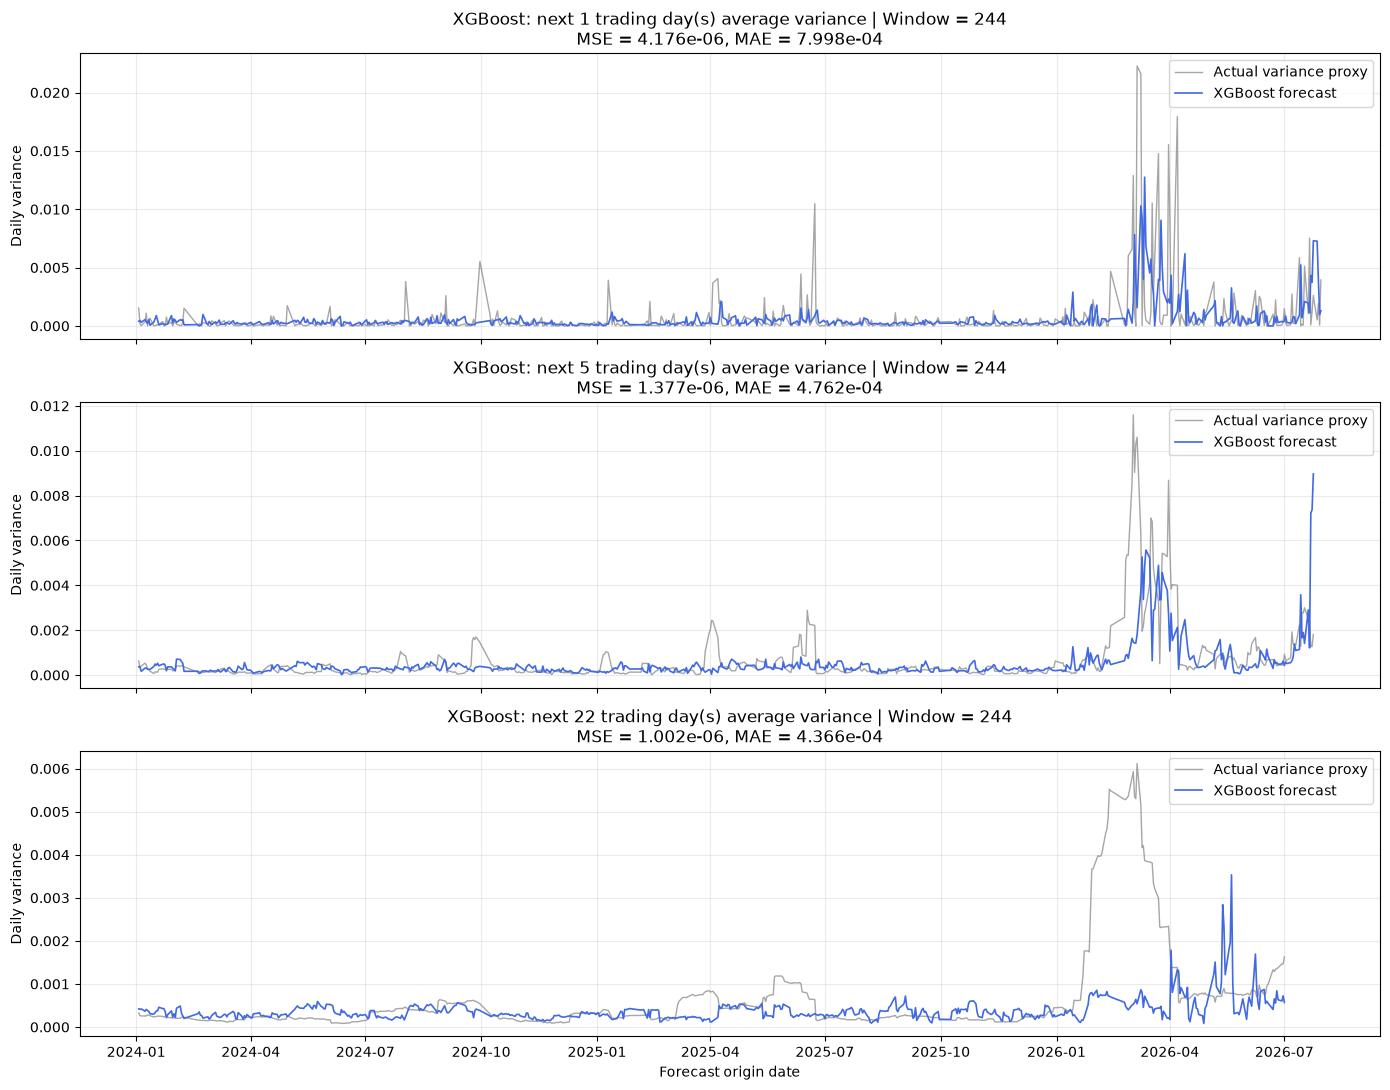

In [71]:
# ============================================================
# 4. 实际值与预测值画图
# ============================================================

fig, axes = plt.subplots(3, 1, figsize=(14, 11), sharex=True)

for ax, h in zip(axes, horizons):

    result = XGB_results[h]

    ax.plot(
        result.index,
        result["actual"],
        color="grey",
        alpha=0.7,
        linewidth=1,
        label="Actual variance proxy"
    )

    ax.plot(
        result.index,
        result["forecast"],
        color="royalblue",
        linewidth=1.2,
        label="XGBoost forecast"
    )

    ax.set_title(
        f"XGBoost: next {h} trading day(s) average variance | "
        f"Window = {window}\n"
        f"MSE = {XGB_metrics.loc[h, 'MSE']:.3e}, "
        f"MAE = {XGB_metrics.loc[h, 'MAE']:.3e}"
    )

    ax.set_ylabel("Daily variance")
    ax.grid(alpha=0.25)
    ax.legend()

axes[-1].set_xlabel("Forecast origin date")

plt.tight_layout()
plt.show()

In [72]:
# ============================================================
# 5. RF 与 XGBoost 指标比较
# ============================================================

RF_XGB_comparison = pd.concat(
    {
        "RF": RF_metrics,
        "XGBoost": XGB_metrics
    },
    names=["model", "horizon"]
)

display(RF_XGB_comparison)

MSE       MAE  N_forecasts
model   horizon                                     
RF      1        3.701543e-06  0.000758        622.0
        5        1.179788e-06  0.000449        618.0
        22       9.787243e-07  0.000434        601.0
XGBoost 1        4.175563e-06  0.000800        622.0
        5        1.377018e-06  0.000476        618.0
        22       1.002245e-06  0.000437        601.0

### DNN + LSTM + GRU

Wang, Z. and Lu, X., 2024. COMEX Copper Futures Volatility Forecasting: Econometric Models and Deep Learning. arXiv preprint arXiv:2409.08356.

In [74]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.preprocessing import MinMaxScaler
from tensorflow import keras
from tensorflow.keras import layers
from IPython.display import display


# ============================================================
# 1. Parameters
# ============================================================

window = 244
horizons = [1, 5, 22]
lookback = 12

epochs = 50
batch_size = 64
learning_rate = 0.0001
seed = 42

# Positive variance floor, relative to each training window's scale
floor_ratio = 1e-8

tf.keras.utils.set_random_seed(seed)

In [79]:
# ============================================================
# 2. Data: daily variance proxy = squared return
# ============================================================

data_NN = r.rename("r").to_frame().sort_index()

data_NN["r"] = pd.to_numeric(data_NN["r"], errors="coerce")
data_NN = data_NN.replace([np.inf, -np.inf], np.nan)

# Initial missing return is common; do not silently remove internal gaps
first_valid = data_NN["r"].first_valid_index()

if first_valid is None:
    raise ValueError("SC['r'] contains no valid returns.")

data_NN = data_NN.loc[first_valid:].copy()

if data_NN["r"].isna().any():
    raise ValueError("SC['r'] has missing returns inside the sample.")

if not data_NN.index.is_unique:
    raise ValueError("SC's date index must be unique.")

data_NN["proxy"] = data_NN["r"] ** 2

proxy_NN = data_NN["proxy"].to_numpy(dtype=float)
dates_NN = data_NN.index

max_horizon = max(horizons)

if window < lookback + max_horizon:
    raise ValueError("window is too short for lookback and horizons.")

if len(data_NN) < window + max_horizon:
    raise ValueError("Not enough data for rolling forecasting.")

In [80]:
# ============================================================
# 3. Construct training pairs entirely within the 244-day window
# ============================================================

def make_training_pairs(scaled_proxy, lookback, horizons):
    """
    Input ending at k:
        [v_(k-lookback+1), ..., v_k]

    Targets:
        [v_(k+1), v_(k+5), v_(k+22)]

    All input values and targets must be inside the current window.
    """
    X, y = [], []
    max_h = max(horizons)

    for k in range(lookback - 1, len(scaled_proxy) - max_h):
        X.append(scaled_proxy[k - lookback + 1 : k + 1])
        y.append([scaled_proxy[k + h] for h in horizons])

    return (
        np.asarray(X, dtype=np.float32),
        np.asarray(y, dtype=np.float32)
    )

In [81]:
# ============================================================
# 4. DNN: 12 -> 16 -> 4 -> 3
# ============================================================

def build_DNN():
    model = keras.Sequential([
        layers.Input(shape=(lookback,)),

        layers.Dense(16),
        layers.LeakyReLU(negative_slope=0.1),
        layers.Dropout(0.2),

        layers.Dense(4),
        layers.LeakyReLU(negative_slope=0.1),

        # Positive scaled forecasts; unlike sigmoid, no upper bound
        layers.Dense(len(horizons), activation="softplus")
    ])

    model.compile(
        optimizer=keras.optimizers.Adam(
            learning_rate=learning_rate
        ),
        loss="mse"
    )

    return model

In [82]:
# ============================================================
# 5. Rolling forecasts
# ============================================================

forecast_records_NN = []

# All horizons use identical forecast origins.
# First origin: the last observation of the first 244-day window.
# Last origin: at least 22 future observations remain.
forecast_origins_NN = range(
    window - 1,
    len(proxy_NN) - max_horizon
)

total_origins_NN = len(forecast_origins_NN)

for roll_number, t in enumerate(forecast_origins_NN, start=1):

    # Current window includes observations through t only
    train_proxy = proxy_NN[t - window + 1 : t + 1]

    variance_floor = max(
        float(np.mean(train_proxy)) * floor_ratio,
        np.finfo(float).tiny
    )

    # Degenerate window: no variation to learn
    if np.ptp(train_proxy) == 0:
        predicted_proxy = np.repeat(
            max(float(train_proxy[0]), variance_floor),
            len(horizons)
        )

    else:
        # Fit scaling using only the current historical window
        scaler = MinMaxScaler(feature_range=(0, 1))

        scaled_proxy = scaler.fit_transform(
            train_proxy.reshape(-1, 1)
        ).ravel()

        X_train, y_train = make_training_pairs(
            scaled_proxy,
            lookback,
            horizons
        )

        # Fresh model for every rolling window
        keras.backend.clear_session()
        tf.keras.utils.set_random_seed(seed)

        model_NN = build_DNN()

        # Paper uses early stopping based on model loss.
        # patience/min_delta are implementation choices here.
        early_stopping = keras.callbacks.EarlyStopping(
            monitor="loss",
            patience=10,
            min_delta=1e-6,
            restore_best_weights=True
        )

        model_NN.fit(
            X_train,
            y_train,
            epochs=epochs,
            batch_size=batch_size,
            shuffle=False,
            callbacks=[early_stopping],
            verbose=0
        )

        # Latest 12 observations, ending at forecast origin t
        X_forecast = scaled_proxy[-lookback:].reshape(1, lookback)
        X_forecast = X_forecast.astype(np.float32)

        predicted_scaled = model_NN(
            X_forecast,
            training=False
        ).numpy().ravel()

        # The scaler was fitted to one variable, so reshape to one column
        predicted_proxy = scaler.inverse_transform(
            predicted_scaled.reshape(-1, 1)
        ).ravel()

        predicted_proxy = np.maximum(
            predicted_proxy,
            variance_floor
        )

    for j, h in enumerate(horizons):
        forecast_records_NN.append({
            "Origin": dates_NN[t],
            "Target": dates_NN[t + h],
            "Horizon": h,
            "Actual": proxy_NN[t + h],
            "Forecast": float(predicted_proxy[j])
        })

    if roll_number == 1 or roll_number % 50 == 0:
        print(
            f"Rolling DNN: {roll_number}/{total_origins_NN}"
        )


forecast_table_NN = pd.DataFrame(forecast_records_NN)

forecast_table_NN = (
    forecast_table_NN
    .sort_values(["Horizon", "Target"])
    .reset_index(drop=True)
)

if not np.isfinite(forecast_table_NN["Forecast"]).all():
    raise RuntimeError("DNN produced non-finite forecasts.")

print("Rolling DNN completed.")
display(forecast_table_NN.head())

Rolling DNN: 1/600
,Rolling DNN: 50/600
,Rolling DNN: 100/600
,Rolling DNN: 150/600
,Rolling DNN: 200/600
,Rolling DNN: 250/600
,Rolling DNN: 300/600
,Rolling DNN: 350/600
,Rolling DNN: 400/600
,Rolling DNN: 450/600
,Rolling DNN: 500/600
,Rolling DNN: 550/600
,Rolling DNN: 600/600
,Rolling DNN completed.


,Origin,Target,Horizon,Actual,Forecast
0,2024-01-04,2024-01-05,1,1.768895,52.221497
1,2024-01-05,2024-01-08,1,0.205527,52.698658
2,2024-01-08,2024-01-09,1,3.501655,53.862846
3,2024-01-09,2024-01-10,1,10.869562,52.426678
4,2024-01-10,2024-01-11,1,0.063084,53.407406


In [83]:
# ============================================================
# 6. Evaluation: MAE, MSE, QLIKE
# ============================================================

evaluation_records_NN = []

for h in horizons:

    result_h = forecast_table_NN.loc[
        forecast_table_NN["Horizon"] == h
    ]

    actual = result_h["Actual"].to_numpy(dtype=float)
    forecast = result_h["Forecast"].to_numpy(dtype=float)

    mae = np.mean(np.abs(actual - forecast))
    mse = np.mean((actual - forecast) ** 2)

    # Paper's equation (16):
    # QLIKE = mean(log(forecast) + actual / forecast - 1)
    qlike = np.mean(
        np.log(forecast) + actual / forecast - 1
    )

    evaluation_records_NN.append({
        "Model": "DNN",
        "Horizon": h,
        "N": len(result_h),
        "MAE": mae,
        "MSE": mse,
        "QLIKE": qlike
    })

evaluation_table_NN = pd.DataFrame(evaluation_records_NN)

display(evaluation_table_NN)

,Model,Horizon,N,MAE,MSE,QLIKE
0,DNN,1,600,60.572958,5106.896030,3.120969
1,DNN,5,600,61.597460,5363.396528,3.132274
2,DNN,22,600,61.145078,5259.981334,3.135060


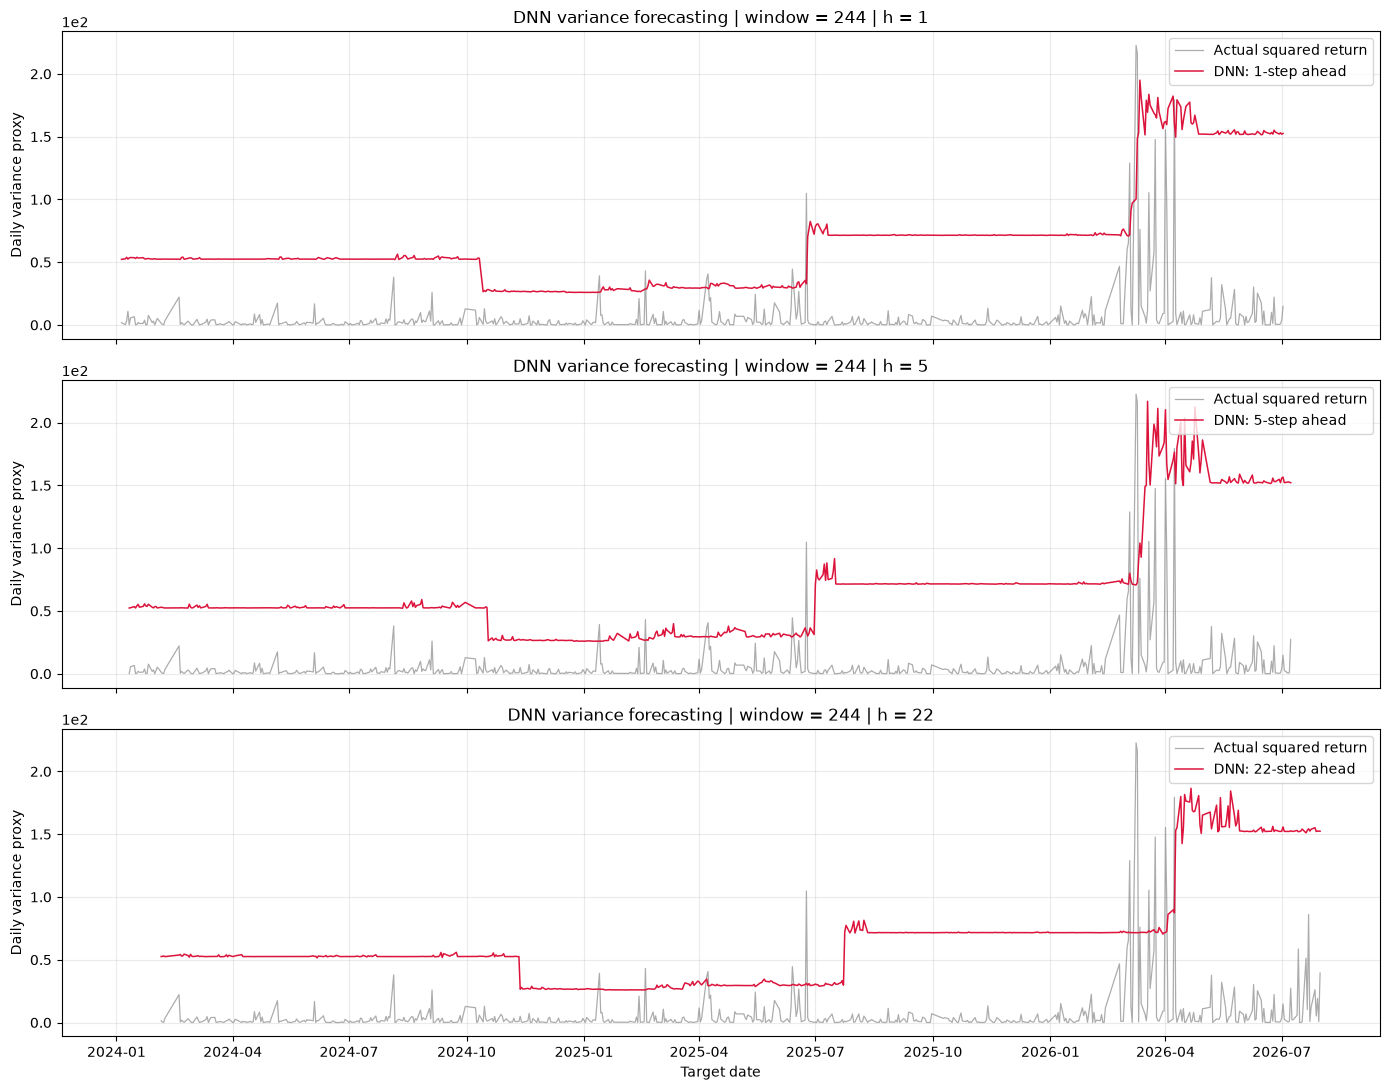

In [84]:
# ============================================================
# 7. Plot forecasts against actual daily squared returns
# ============================================================

fig, axes = plt.subplots(
    3, 1,
    figsize=(14, 11),
    sharex=True
)

for ax, h in zip(axes, horizons):

    result_h = forecast_table_NN.loc[
        forecast_table_NN["Horizon"] == h
    ].sort_values("Target")

    ax.plot(
        result_h["Target"],
        result_h["Actual"],
        label="Actual squared return",
        color="gray",
        linewidth=0.9,
        alpha=0.65
    )

    ax.plot(
        result_h["Target"],
        result_h["Forecast"],
        label=f"DNN: {h}-step ahead",
        color="crimson",
        linewidth=1.1
    )

    ax.set_title(
        f"DNN variance forecasting | window = {window} | h = {h}"
    )
    ax.set_ylabel("Daily variance proxy")
    ax.grid(alpha=0.25)
    ax.legend(loc="upper right")
    ax.ticklabel_format(
        axis="y",
        style="sci",
        scilimits=(0, 0)
    )

axes[-1].set_xlabel("Target date")

plt.tight_layout()
plt.show()

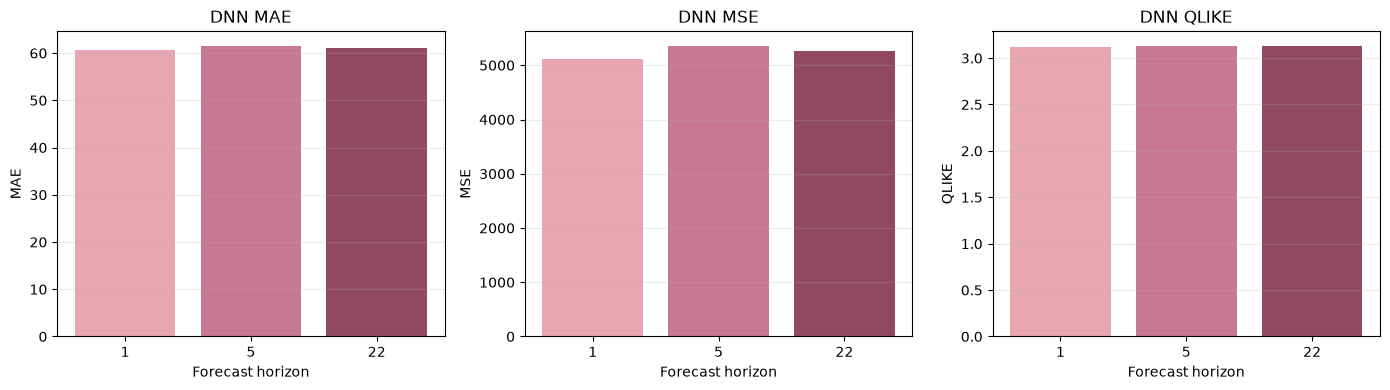

In [85]:
# ============================================================
# 8. Plot evaluation metrics
# ============================================================

fig, axes = plt.subplots(1, 3, figsize=(14, 4))

for ax, metric in zip(axes, ["MAE", "MSE", "QLIKE"]):

    ax.bar(
        evaluation_table_NN["Horizon"].astype(str),
        evaluation_table_NN[metric],
        color=["#E8A6B2", "#C77991", "#914963"]
    )

    ax.set_title(f"DNN {metric}")
    ax.set_xlabel("Forecast horizon")
    ax.set_ylabel(metric)
    ax.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()

### LSTM

In [86]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.preprocessing import MinMaxScaler
from tensorflow import keras
from tensorflow.keras import layers
from IPython.display import display


# ============================================================
# 1. Parameters and data
# ============================================================

window = 244
horizons = [1, 5, 22]
lookback = 12
max_horizon = max(horizons)

epochs = 50
batch_size = 16
learning_rate = 0.0001
seed = 42
floor_ratio = 1e-8

# Reuse the cleaned data from the DNN implementation
data_LSTM = data_NN[["r", "proxy"]].copy().sort_index()

proxy_LSTM = data_LSTM["proxy"].to_numpy(dtype=float)
dates_LSTM = data_LSTM.index

if not dates_LSTM.is_unique:
    raise ValueError("Date index must be unique.")

if not np.isfinite(proxy_LSTM).all():
    raise ValueError("proxy contains missing or infinite values.")

if np.any(proxy_LSTM < 0):
    raise ValueError("Variance proxy must be nonnegative.")

if len(data_LSTM) < window + max_horizon:
    raise ValueError("Not enough data for rolling forecasting.")

In [87]:
# ============================================================
# 2. Training pairs
# ============================================================

def make_LSTM_training_pairs(scaled_proxy):
    X, y = [], []

    for k in range(lookback - 1, len(scaled_proxy) - max_horizon):

        # Past 12 daily variance proxies
        X.append(
            scaled_proxy[k - lookback + 1 : k + 1]
        )

        # Future day 1, day 5 and day 22 proxies
        y.append([
            scaled_proxy[k + h]
            for h in horizons
        ])

    # LSTM input: (samples, sequence length, features)
    X = np.asarray(X, dtype=np.float32)
    X = X.reshape(-1, lookback, 1)

    y = np.asarray(y, dtype=np.float32)

    return X, y

In [88]:
# ============================================================
# 3. LSTM architecture
# ============================================================

def build_LSTM():
    model = keras.Sequential([
        layers.Input(shape=(lookback, 1)),

        layers.LSTM(
            units=8,
            activation="tanh",
            recurrent_activation="sigmoid",
            return_sequences=False,
            stateful=False
        ),

        layers.Dropout(0.2),

        # Three direct forecasts: h = 1, 5, 22
        layers.Dense(
            units=len(horizons),
            activation="softplus"
        )
    ])

    model.compile(
        optimizer=keras.optimizers.Adam(
            learning_rate=learning_rate
        ),
        loss="mse"
    )

    return model

In [89]:
# ============================================================
# 4. Rolling forecasts: window = 244, move forward one day
# ============================================================

forecast_records_LSTM = []

# Same forecast origins as the previous DNN implementation
forecast_origins_LSTM = range(
    window - 1,
    len(proxy_LSTM) - max_horizon
)

total_origins_LSTM = len(forecast_origins_LSTM)

for roll_number, t in enumerate(forecast_origins_LSTM, start=1):

    # Historical observations through t only
    train_proxy = proxy_LSTM[t - window + 1 : t + 1]

    variance_floor = max(
        float(np.mean(train_proxy)) * floor_ratio,
        np.finfo(float).tiny
    )

    if np.ptp(train_proxy) == 0:

        predicted_proxy = np.repeat(
            max(float(train_proxy[0]), variance_floor),
            len(horizons)
        )

    else:

        # Fit scaler within this historical window only
        scaler_LSTM = MinMaxScaler()

        scaled_proxy = scaler_LSTM.fit_transform(
            train_proxy.reshape(-1, 1)
        ).ravel()

        X_train, y_train = make_LSTM_training_pairs(
            scaled_proxy
        )

        # Retrain a fresh model at every forecast origin
        keras.backend.clear_session()
        tf.keras.utils.set_random_seed(seed)

        model_LSTM = build_LSTM()

        early_stopping_LSTM = keras.callbacks.EarlyStopping(
            monitor="loss",
            patience=10,
            min_delta=1e-6,
            restore_best_weights=True
        )

        model_LSTM.fit(
            X_train,
            y_train,
            epochs=epochs,
            batch_size=batch_size,
            shuffle=False,
            callbacks=[early_stopping_LSTM],
            verbose=0
        )

        # Latest 12 observations available at time t
        X_forecast = scaled_proxy[-lookback:].reshape(
            1, lookback, 1
        ).astype(np.float32)

        predicted_scaled = model_LSTM(
            X_forecast,
            training=False
        ).numpy().ravel()

        predicted_proxy = scaler_LSTM.inverse_transform(
            predicted_scaled.reshape(-1, 1)
        ).ravel()

        predicted_proxy = np.maximum(
            predicted_proxy,
            variance_floor
        )

    for j, h in enumerate(horizons):

        forecast_records_LSTM.append({
            "Origin": dates_LSTM[t],
            "Target": dates_LSTM[t + h],
            "Horizon": h,
            "Actual": proxy_LSTM[t + h],
            "Forecast": float(predicted_proxy[j])
        })

    if (
        roll_number == 1
        or roll_number % 50 == 0
        or roll_number == total_origins_LSTM
    ):
        print(
            f"Rolling LSTM: {roll_number}/{total_origins_LSTM}"
        )


forecast_table_LSTM = (
    pd.DataFrame(forecast_records_LSTM)
    .sort_values(["Horizon", "Target"])
    .reset_index(drop=True)
)

if not np.isfinite(forecast_table_LSTM["Forecast"]).all():
    raise RuntimeError("LSTM produced non-finite forecasts.")

display(forecast_table_LSTM.head())

Rolling LSTM: 1/600
,Rolling LSTM: 50/600
,Rolling LSTM: 100/600
,Rolling LSTM: 150/600
,Rolling LSTM: 200/600
,Rolling LSTM: 250/600
,Rolling LSTM: 300/600
,Rolling LSTM: 350/600
,Rolling LSTM: 400/600
,Rolling LSTM: 450/600
,Rolling LSTM: 500/600
,Rolling LSTM: 550/600
,Rolling LSTM: 600/600


,Origin,Target,Horizon,Actual,Forecast
0,2024-01-04,2024-01-05,1,1.768895,20.042545
1,2024-01-05,2024-01-08,1,0.205527,20.015547
2,2024-01-08,2024-01-09,1,3.501655,20.234262
3,2024-01-09,2024-01-10,1,10.869562,20.100161
4,2024-01-10,2024-01-11,1,0.063084,19.876736


In [90]:
# ============================================================
# 5. MAE, MSE, QLIKE
# ============================================================

evaluation_records_LSTM = []

for h in horizons:

    result_h = forecast_table_LSTM.loc[
        forecast_table_LSTM["Horizon"] == h
    ]

    actual = result_h["Actual"].to_numpy(dtype=float)
    forecast = result_h["Forecast"].to_numpy(dtype=float)

    mae = np.mean(np.abs(actual - forecast))
    mse = np.mean((actual - forecast) ** 2)

    # Same QLIKE definition as the previous DNN code:
    # paper equation (16)
    qlike = np.mean(
        np.log(forecast) + actual / forecast - 1
    )

    evaluation_records_LSTM.append({
        "Model": "LSTM",
        "Horizon": h,
        "N": len(result_h),
        "MAE": mae,
        "MSE": mse,
        "QLIKE": qlike
    })

evaluation_table_LSTM = pd.DataFrame(
    evaluation_records_LSTM
)

# Add LSTM results while preserving existing model results
if (
    "evaluation_table" in globals()
    and isinstance(evaluation_table, pd.DataFrame)
    and "Model" in evaluation_table.columns
):
    evaluation_table = pd.concat(
        [
            evaluation_table.loc[
                evaluation_table["Model"] != "LSTM"
            ],
            evaluation_table_LSTM
        ],
        ignore_index=True
    )
else:
    evaluation_table = evaluation_table_LSTM.copy()

display(evaluation_table)

,Model,Horizon,N,MAE,MSE,QLIKE
0,LSTM,1,600,23.395895,940.813694,2.315954
1,LSTM,5,600,43.066981,2656.224624,2.829389
2,LSTM,22,600,33.659600,1730.145465,2.629252


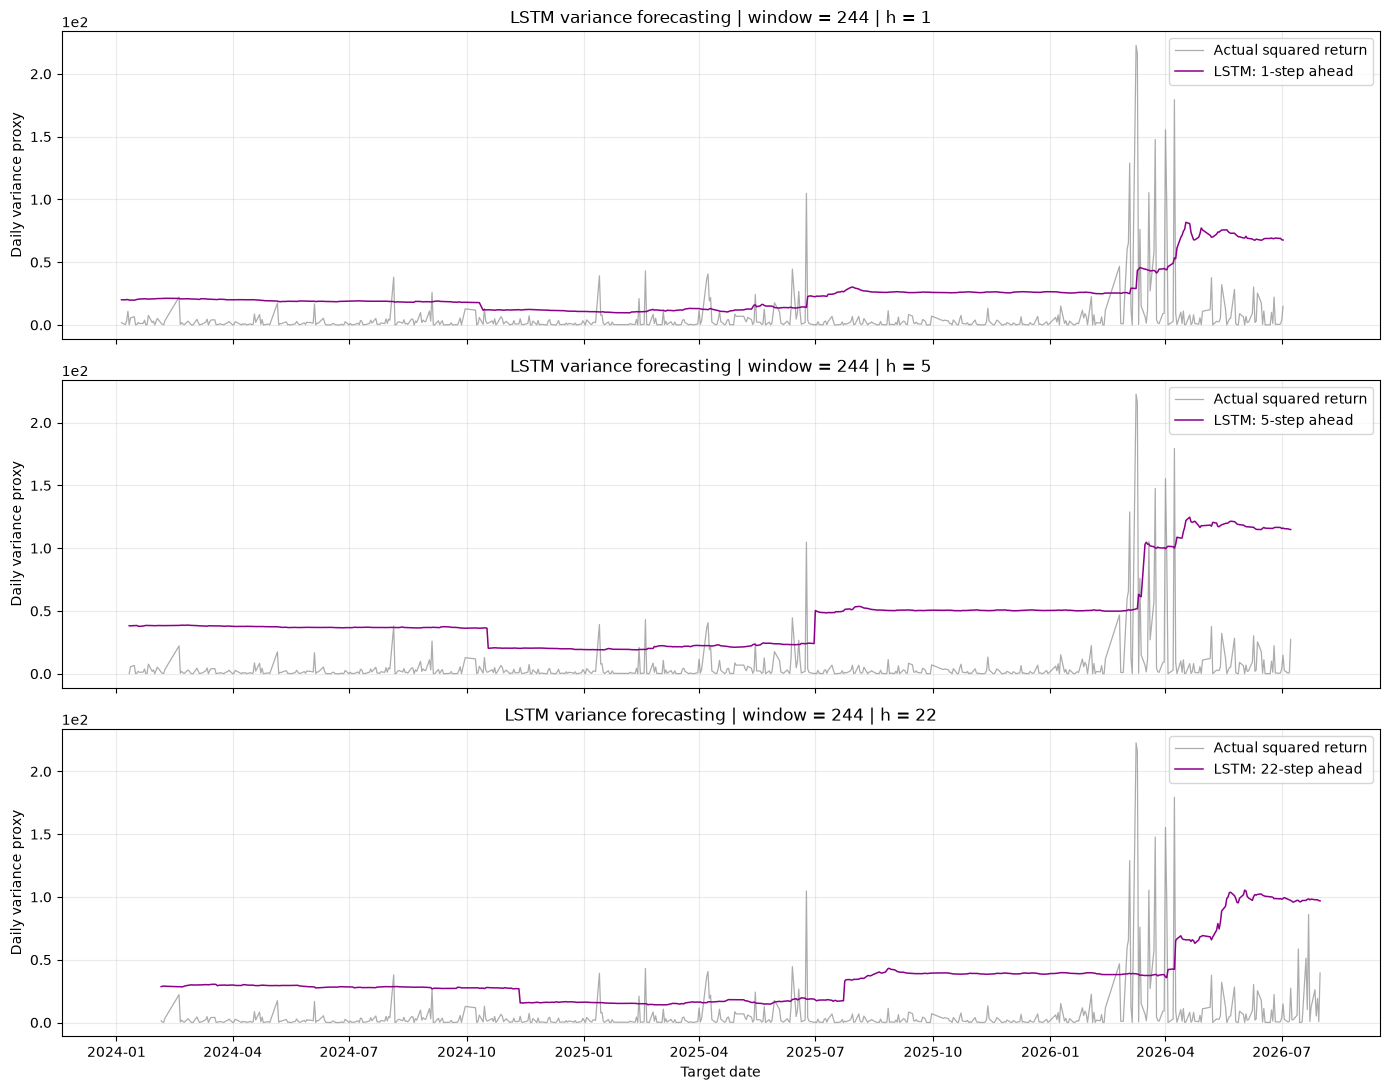

In [91]:
# ============================================================
# 6. Forecast plots
# ============================================================

fig, axes = plt.subplots(
    3, 1,
    figsize=(14, 11),
    sharex=True
)

for ax, h in zip(axes, horizons):

    result_h = forecast_table_LSTM.loc[
        forecast_table_LSTM["Horizon"] == h
    ].sort_values("Target")

    ax.plot(
        result_h["Target"],
        result_h["Actual"],
        color="gray",
        linewidth=0.9,
        alpha=0.65,
        label="Actual squared return"
    )

    ax.plot(
        result_h["Target"],
        result_h["Forecast"],
        color="darkmagenta",
        linewidth=1.1,
        label=f"LSTM: {h}-step ahead"
    )

    ax.set_title(
        f"LSTM variance forecasting | window = {window} | h = {h}"
    )
    ax.set_ylabel("Daily variance proxy")
    ax.grid(alpha=0.25)
    ax.legend(loc="upper right")

    ax.ticklabel_format(
        axis="y",
        style="sci",
        scilimits=(0, 0)
    )

axes[-1].set_xlabel("Target date")

plt.tight_layout()
plt.show()

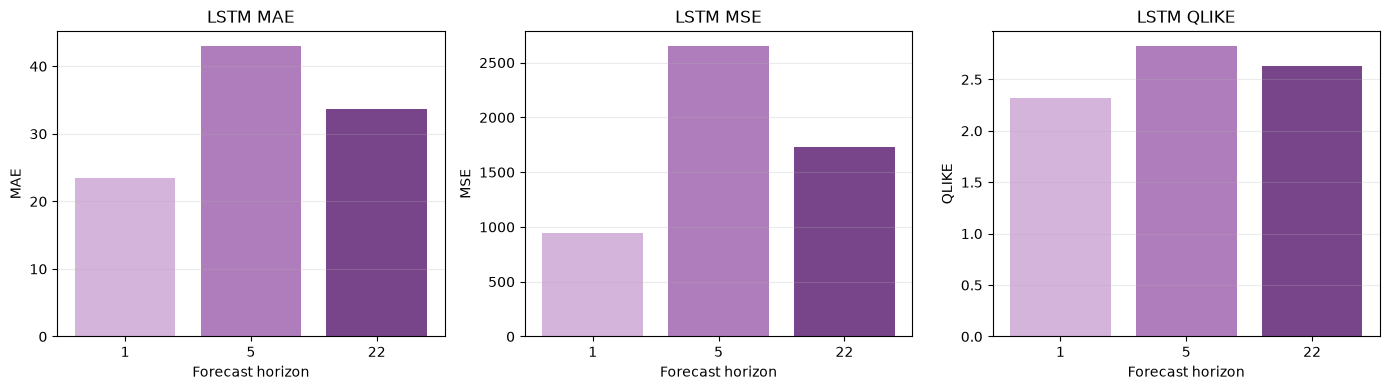

In [92]:
# ============================================================
# 7. Evaluation plots
# ============================================================

fig, axes = plt.subplots(1, 3, figsize=(14, 4))

for ax, metric in zip(axes, ["MAE", "MSE", "QLIKE"]):

    ax.bar(
        evaluation_table_LSTM["Horizon"].astype(str),
        evaluation_table_LSTM[metric],
        color=["#D5B4DC", "#AF7DBB", "#79458A"]
    )

    ax.set_title(f"LSTM {metric}")
    ax.set_xlabel("Forecast horizon")
    ax.set_ylabel(metric)
    ax.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()

### GRU

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.preprocessing import MinMaxScaler
from tensorflow import keras
from tensorflow.keras import layers
from IPython.display import display


# ============================================================
# 1. Parameters and data
# ============================================================

window = 244
horizons = [1, 5, 22]
lookback = 12
max_horizon = max(horizons)

epochs = 50
batch_size = 64
learning_rate = 0.0001
seed = 42
floor_ratio = 1e-8

# Reuse cleaned data from the DNN implementation
data_GRU = data_NN[["r", "proxy"]].copy().sort_index()

proxy_GRU = data_GRU["proxy"].to_numpy(dtype=float)
dates_GRU = data_GRU.index

if not dates_GRU.is_unique:
    raise ValueError("Date index must be unique.")

if not np.isfinite(proxy_GRU).all():
    raise ValueError("proxy contains missing or infinite values.")

if np.any(proxy_GRU < 0):
    raise ValueError("Variance proxy must be nonnegative.")

if len(data_GRU) < window + max_horizon:
    raise ValueError("Not enough data for rolling forecasting.")

In [ ]:
# ============================================================
# 2. Training pairs
# ============================================================

def make_GRU_training_pairs(scaled_proxy):
    X, y = [], []

    for k in range(lookback - 1, len(scaled_proxy) - max_horizon):

        X.append(
            scaled_proxy[k - lookback + 1 : k + 1]
        )

        y.append([
            scaled_proxy[k + h]
            for h in horizons
        ])

    # GRU input: (samples, sequence length, features)
    X = np.asarray(X, dtype=np.float32).reshape(
        -1, lookback, 1
    )
    y = np.asarray(y, dtype=np.float32)

    return X, y

In [ ]:
# ============================================================
# 3. GRU architecture
# ============================================================

def build_GRU():
    model = keras.Sequential([
        layers.Input(shape=(lookback, 1)),

        layers.GRU(
            units=16,
            activation="tanh",
            recurrent_activation="sigmoid",
            return_sequences=False,
            stateful=False
        ),

        layers.Dropout(0.2),

        layers.Dense(4),
        layers.LeakyReLU(negative_slope=0.1),

        # Positive direct forecasts for h = 1, 5, 22
        layers.Dense(
            units=len(horizons),
            activation="softplus"
        )
    ])

    model.compile(
        optimizer=keras.optimizers.Adam(
            learning_rate=learning_rate
        ),
        loss="mse"
    )

    return model

In [ ]:
# ============================================================
# 4. Rolling forecasts
# ============================================================

forecast_records_GRU = []

# Identical forecast origins to the DNN and LSTM implementations
forecast_origins_GRU = range(
    window - 1,
    len(proxy_GRU) - max_horizon
)

total_origins_GRU = len(forecast_origins_GRU)

for roll_number, t in enumerate(forecast_origins_GRU, start=1):

    # Latest 244 observations through forecast origin t
    train_proxy = proxy_GRU[t - window + 1 : t + 1]

    variance_floor = max(
        float(np.mean(train_proxy)) * floor_ratio,
        np.finfo(float).tiny
    )

    if np.ptp(train_proxy) == 0:

        predicted_proxy = np.repeat(
            max(float(train_proxy[0]), variance_floor),
            len(horizons)
        )

    else:

        # Scaling uses this historical window only
        scaler_GRU = MinMaxScaler()

        scaled_proxy = scaler_GRU.fit_transform(
            train_proxy.reshape(-1, 1)
        ).ravel()

        X_train, y_train = make_GRU_training_pairs(
            scaled_proxy
        )

        # Fresh model at every forecast origin
        keras.backend.clear_session()
        tf.keras.utils.set_random_seed(seed)

        model_GRU = build_GRU()

        # Training-loss stopping, as in the previous implementations
        early_stopping_GRU = keras.callbacks.EarlyStopping(
            monitor="loss",
            patience=10,
            min_delta=1e-6,
            restore_best_weights=True
        )

        model_GRU.fit(
            X_train,
            y_train,
            epochs=epochs,
            batch_size=batch_size,
            shuffle=False,
            callbacks=[early_stopping_GRU],
            verbose=0
        )

        # Latest 12 observations available at t
        X_forecast = scaled_proxy[-lookback:].reshape(
            1, lookback, 1
        ).astype(np.float32)

        predicted_scaled = model_GRU(
            X_forecast,
            training=False
        ).numpy().ravel()

        predicted_proxy = scaler_GRU.inverse_transform(
            predicted_scaled.reshape(-1, 1)
        ).ravel()

        predicted_proxy = np.maximum(
            predicted_proxy,
            variance_floor
        )

    for j, h in enumerate(horizons):

        forecast_records_GRU.append({
            "Origin": dates_GRU[t],
            "Target": dates_GRU[t + h],
            "Horizon": h,
            "Actual": proxy_GRU[t + h],
            "Forecast": float(predicted_proxy[j])
        })

    if (
        roll_number == 1
        or roll_number % 50 == 0
        or roll_number == total_origins_GRU
    ):
        print(
            f"Rolling GRU: {roll_number}/{total_origins_GRU}"
        )


forecast_table_GRU = (
    pd.DataFrame(forecast_records_GRU)
    .sort_values(["Horizon", "Target"])
    .reset_index(drop=True)
)

if not np.isfinite(forecast_table_GRU["Forecast"]).all():
    raise RuntimeError("GRU produced non-finite forecasts.")

display(forecast_table_GRU.head())

In [ ]:
# ============================================================
# 5. MAE, MSE, QLIKE
# ============================================================

evaluation_records_GRU = []

for h in horizons:

    result_h = forecast_table_GRU.loc[
        forecast_table_GRU["Horizon"] == h
    ]

    actual = result_h["Actual"].to_numpy(dtype=float)
    forecast = result_h["Forecast"].to_numpy(dtype=float)

    mae = np.mean(np.abs(actual - forecast))
    mse = np.mean((actual - forecast) ** 2)

    # Paper equation (16), same as the DNN/LSTM code
    qlike = np.mean(
        np.log(forecast) + actual / forecast - 1
    )

    evaluation_records_GRU.append({
        "Model": "GRU",
        "Horizon": h,
        "N": len(result_h),
        "MAE": mae,
        "MSE": mse,
        "QLIKE": qlike
    })

evaluation_table_GRU = pd.DataFrame(
    evaluation_records_GRU
)

# Preserve previous models; replace GRU rows on rerun
if (
    "evaluation_table" in globals()
    and isinstance(evaluation_table, pd.DataFrame)
    and "Model" in evaluation_table.columns
):
    evaluation_table = pd.concat(
        [
            evaluation_table.loc[
                evaluation_table["Model"] != "GRU"
            ],
            evaluation_table_GRU
        ],
        ignore_index=True
    )
else:
    evaluation_table = evaluation_table_GRU.copy()

display(evaluation_table)

In [ ]:
# ============================================================
# 6. Forecast plots
# ============================================================

fig, axes = plt.subplots(
    3, 1,
    figsize=(14, 11),
    sharex=True
)

for ax, h in zip(axes, horizons):

    result_h = forecast_table_GRU.loc[
        forecast_table_GRU["Horizon"] == h
    ].sort_values("Target")

    ax.plot(
        result_h["Target"],
        result_h["Actual"],
        color="gray",
        linewidth=0.9,
        alpha=0.65,
        label="Actual squared return"
    )

    ax.plot(
        result_h["Target"],
        result_h["Forecast"],
        color="teal",
        linewidth=1.1,
        label=f"GRU: {h}-step ahead"
    )

    ax.set_title(
        f"GRU variance forecasting | window = {window} | h = {h}"
    )
    ax.set_ylabel("Daily variance proxy")
    ax.grid(alpha=0.25)
    ax.legend(loc="upper right")

    ax.ticklabel_format(
        axis="y",
        style="sci",
        scilimits=(0, 0)
    )

axes[-1].set_xlabel("Target date")

plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# 7. Evaluation plots
# ============================================================

fig, axes = plt.subplots(1, 3, figsize=(14, 4))

for ax, metric in zip(axes, ["MAE", "MSE", "QLIKE"]):

    ax.bar(
        evaluation_table_GRU["Horizon"].astype(str),
        evaluation_table_GRU[metric],
        color=["#B5DAD5", "#72B7AD", "#347F76"]
    )

    ax.set_title(f"GRU {metric}")
    ax.set_xlabel("Forecast horizon")
    ax.set_ylabel(metric)
    ax.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()

In [77]:
SC.head()

,date,underlying,open,high,low,close,settlement,prev_settlement,volume,total_turnover,open_interest,return
0,2023-01-03,sc2302,568.2,571.5,563.3,567.1,566.6,552.8,29554.0,1.674696e+10,19216.0,0.007611
1,2023-01-04,sc2303,567.8,570.1,539.8,542.1,556.1,572.0,124436.0,6.921035e+10,30405.0,-0.053863
2,2023-01-05,sc2303,530.0,534.2,522.5,524.1,527.5,556.1,143079.0,7.547692e+10,36733.0,-0.033768
3,2023-01-06,sc2303,526.9,531.8,519.4,528.8,525.7,527.5,143323.0,7.535326e+10,36664.0,0.008928
4,2023-01-09,sc2303,523.5,534.1,522.0,526.3,527.9,525.7,145187.0,7.665258e+10,36737.0,-0.004739
